# Investigating Non-Local Coding via Partially Overlapping Flight Trajectories

Find pairs of flight trajectory clusters that share a contiguous spatial segment but diverge elsewhere. By comparing neural activity in the shared vs. divergent portions, we test whether hippocampal neurons encode more than just current position (non-local / trajectory-dependent coding).

**Approach:**
- Load raw .mat files directly (no z-scoring, positions in meters)
- Use existing `FlightClusters` to get cluster labels
- Sliding-window Frechet distance on cluster-mean trajectories to identify shared segments
- Align raw spike times to shared segment onset
- Permutation tests: position should NOT differ in shared segment; PSTHs may differ

In [ ]:
import sys
sys.path.insert(0, '/home/alowet/Documents/code/digitalbat')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.io import loadmat
from scipy.interpolate import interp1d
from scipy.ndimage import label as ndlabel
from itertools import combinations
import glob

from digitalbat.utility.utils import frechet_distance, compute_fractional_abscissa, FlightClusters

sns.set_theme(style='whitegrid', context='notebook')

# --- Constants ---
PARENT_FOLDER = '/mnt/s5/Adam/Angelo/NP_datasets/'
SESSION_NAMES = [
    'Dataset_3_14543_240419',
    'Dataset_3_14543_240420',
    'Dataset_3_14543_240421',
    'Dataset_3_29959_240402',
    'Dataset_3_29959_240403',
    'Dataset_3_29959_240404',
    'Dataset_2_14445_231208',
    'Dataset_2_14445_231209',
    'Dataset_1_32622_231009',
    'Dataset_1_32622_231010',
]
MIN_FLIGHT_DUR = 1.0   # seconds — minimum flight duration to keep
N_DS = 100              # downsample resolution for trajectory comparison
WINDOW_FRAC = 0.30      # sliding window = 30% of trajectory
MIN_CLUSTER_SIZE = 3    # minimum flights per cluster for comparison

## Helper Functions

In [ ]:
def load_session_data(session_name, parent_folder=PARENT_FOLDER):
    """Load raw behavior + spike data from .mat files for one session.
    
    Uses Data_Prep_for_Raw for behavior loading and spike merging logic,
    but returns raw spike times (not binned) for raster plots.
    """
    from digitalbat.datasets.data import Data_Prep_for_Raw

    session_folder = parent_folder + session_name
    su_file_path = parent_folder + 'To_transfer/out_Gunits_probe*_' + session_name + '_with_metrics.mat'

    # Use Data_Prep_for_Raw just to get behavior and spike infrastructure
    prep = Data_Prep_for_Raw(
        parent_folder=session_folder,
        su_file_path=su_file_path,
        use_speed_head_dir=False,
        use_IMU_flag=False,
        use_click_flag=False,
        use_LFP_flag=False,
        use_ripple_flag=False,
        only_flight_flag=False,  # we want all data, we'll segment flights ourselves
        spike_count_flag=True,
        bin_width=0.01,  # irrelevant for us but required
    )
    # Load behavior (sets up bhv dict internally)
    prep.get_all_behavior()

    # Load raw behavior .mat for direct access to positions/velocity at native Fs
    bhv_file = glob.glob(session_folder + '/Extracted_Behavior_*.mat')[0]
    bhv = loadmat(bhv_file)
    r = bhv['r']                        # (N, 3) positions in meters
    if 'Dataset_2' in session_name:
        t_bhv = bhv['t'][:, 0]
    else:
        t_bhv = bhv['t'][0, :]
    bflying = bhv['bflying'][:, 0].astype(int)
    Fs = float(bhv['Fs'][0, 0])
    v = bhv['v']                        # (N, 3) velocity in m/s
    r_lim = bhv['r_lim']

    # --- Raw spike times (reuse Data_Prep_for_Raw's loading + merge logic) ---
    # The spike loading/merging code in get_all_spike() bins spikes,
    # but we need raw times. Replicate just the load+merge part.
    su_paths = sorted(glob.glob(su_file_path))
    su_goods_time = []
    su_goods_cluster_id = []
    su_goods_pType = []
    for p in su_paths:
        su = loadmat(p)
        gu = su['out_Gunits']
        su_goods_cluster_id.append(
            np.array([x[0][0, 0] for x in gu['cluster_id']]))
        su_goods_time.append(
            [x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        su_goods_pType.append(list(np.array(
            [np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
             else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))

    # Merge units (same logic as Data_Prep_for_Raw.get_all_spike)
    merges_file = glob.glob(session_folder + '/merges_Dataset_*.mat')[0]
    merges = loadmat(merges_file)
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(merges['merges'][ii][0]):
            cids_to_merge = merges['merges'][ii][0][0][0][0]
            cid_list = su_goods_cluster_id[ii]
            time_list = su_goods_time[ii]
            merge_idx = [np.where(cid_list == cid)[0][0] for cid in cids_to_merge]
            merged = np.sort(np.concatenate([time_list[idx] for idx in merge_idx]))
            clean = [merged[0]]
            for spk_t in merged[1:]:
                if spk_t - clean[-1] > refractory:
                    clean.append(spk_t)
            time_list[merge_idx[0]] = np.array(clean)
            for idx in merge_idx[1:]:
                time_list[idx] = np.array([])
            valid = [i for i, st in enumerate(time_list) if len(st) > 0]
            su_goods_time[ii] = [time_list[i] for i in valid]
            su_goods_cluster_id[ii] = cid_list[valid]
            su_goods_pType[ii] = [su_goods_pType[ii][i] for i in valid]

    spike_times = [st for probe in su_goods_time for st in probe]
    pType = np.array([pt for probe in su_goods_pType for pt in probe], dtype=object)

    return dict(r=r, t=t_bhv, bflying=bflying, Fs=Fs, v=v, r_lim=r_lim,
                spike_times=spike_times, pType=pType)


def segment_flights(bflying, Fs, min_dur=MIN_FLIGHT_DUR):
    """Find flight start/stop indices from binary bflying vector.
    Returns arrays of start and stop indices (inclusive)."""
    bfly = bflying.astype(int)
    starts = np.where(np.diff(bfly) > 0)[0] + 1
    stops = np.where(np.diff(bfly) < 0)[0]
    if bfly[0] > 0:
        starts = np.concatenate([[0], starts])
    if bfly[-1] > 0:
        stops = np.concatenate([stops, [len(bfly) - 1]])
    n = min(len(starts), len(stops))
    starts, stops = starts[:n], stops[:n]
    durs = (stops - starts) / Fs
    keep = durs >= min_dur
    return starts[keep], stops[keep]


def downsample_trajectory(r, f_start, f_stop, n_ds=N_DS):
    """Downsample a single flight trajectory to n_ds evenly spaced points."""
    f_start, f_stop = int(f_start), int(f_stop)
    traj = r[f_start:f_stop + 1]
    t_orig = np.linspace(0, 1, traj.shape[0])
    t_ds = np.linspace(0, 1, n_ds)
    return np.column_stack([
        interp1d(t_orig, traj[:, d], kind='linear')(t_ds) for d in range(3)])


def downsample_velocity(v, f_start, f_stop, n_ds=N_DS):
    """Downsample a single flight velocity to n_ds evenly spaced points."""
    f_start, f_stop = int(f_start), int(f_stop)
    vel = v[f_start:f_stop + 1]
    t_orig = np.linspace(0, 1, vel.shape[0])
    t_ds = np.linspace(0, 1, n_ds)
    return np.column_stack([
        interp1d(t_orig, vel[:, d], kind='linear')(t_ds) for d in range(3)])


def sliding_window_frechet(traj_a, traj_b, window_frac=WINDOW_FRAC):
    """Compute sliding-window Frechet distance between two (N_DS, 3) trajectories."""
    n = len(traj_a)
    half_win = int(n * window_frac) // 2
    local_frechet = np.full(n, np.nan)
    for i in range(n):
        lo = max(0, i - half_win)
        hi = min(n, i + half_win + 1)
        local_frechet[i] = frechet_distance(traj_a[lo:hi], traj_b[lo:hi])
    return local_frechet


def find_shared_segment(local_frechet, threshold):
    """Find the largest contiguous segment where local_frechet < threshold.
    Returns (start_idx, end_idx) or None."""
    below = (local_frechet < threshold).astype(int)
    labeled, n_components = ndlabel(below)
    if n_components == 0:
        return None
    best_label, best_size = 0, 0
    for lbl in range(1, n_components + 1):
        size = np.sum(labeled == lbl)
        if size > best_size:
            best_label, best_size = lbl, size
    indices = np.where(labeled == best_label)[0]
    return indices[0], indices[-1]


print("Helper functions defined.")


Helper functions defined.


## Scan All Sessions for Candidate Pairs

Loop over every session, cluster flights, compute sliding-window Frechet between
cluster-mean trajectories, and collect all qualifying pairs. Rank by attractiveness
(overlap fraction near 50%, many flights, similar velocities in shared segment).

In [ ]:
# Scan all sessions for partially overlapping cluster pairs
THRESHOLDS_TO_TRY = np.arange(0.3, 1.0, 0.1)  # sweep thresholds per session

all_candidates = []  # collect across all sessions
session_data_cache = {}  # cache loaded data for later use

for session_name in SESSION_NAMES:
    print(f'\n{"=" * 60}')
    print(f'Processing {session_name}...')

    # Load data
    try:
        data = load_session_data(session_name)
    except Exception as e:
        print(f'  ERROR loading: {e}')
        continue

    r_sess = data['r']
    v_sess = data['v']
    Fs_sess = data['Fs']

    # Cluster flights
    fc = FlightClusters(r_vector=r_sess, f_vector=data['bflying'], Fs=Fs_sess,
                        frechet_clus=True, alpha=0.8)
    fc_results = fc.compute()
    f_starts = fc_results['start_frame']
    f_stops = fc_results['stop_frame']
    cids = fc_results['id']

    # Build df_flights for this session
    flight_records = []
    for i in range(fc_results['N']):
        dur = (f_stops[i] - f_starts[i]) / Fs_sess
        if dur >= MIN_FLIGHT_DUR:
            flight_records.append(dict(
                flight_idx=i, cluster_id=cids[i],
                f_start=f_starts[i], f_stop=f_stops[i],
                duration=dur, n_samples=f_stops[i] - f_starts[i] + 1))
    df_fl = pd.DataFrame(flight_records)
    print(f'  {len(df_fl)} flights (>= {MIN_FLIGHT_DUR}s)')

    # Mean trajectory per cluster (only clusters with enough flights)
    cluster_info = {}
    for cid, grp in df_fl.groupby('cluster_id'):
        if len(grp) < MIN_CLUSTER_SIZE:
            continue
        trajs_ds = np.stack([downsample_trajectory(r_sess, row.f_start, row.f_stop)
                             for _, row in grp.iterrows()])
        vels_ds = np.stack([downsample_velocity(v_sess, row.f_start, row.f_stop)
                            for _, row in grp.iterrows()])
        cluster_info[cid] = dict(
            n_flights=len(grp),
            mean_traj=np.nanmean(trajs_ds, axis=0),
            mean_vel=np.nanmean(vels_ds, axis=0))

    valid_cids = list(cluster_info.keys())
    print(f'  {len(valid_cids)} clusters with >= {MIN_CLUSTER_SIZE} flights: {valid_cids}')
    if len(valid_cids) < 2:
        continue

    # Pairwise sliding-window Frechet
    for ci, cj in combinations(valid_cids, 2):
        lf_pos = sliding_window_frechet(
            cluster_info[ci]['mean_traj'], cluster_info[cj]['mean_traj'])
        lf_vel = sliding_window_frechet(
            cluster_info[ci]['mean_vel'], cluster_info[cj]['mean_vel'])

        # Try multiple thresholds, keep the best overlap
        best = None
        for th in THRESHOLDS_TO_TRY:
            seg = find_shared_segment(lf_pos, th)
            if seg is None:
                continue
            overlap = (seg[1] - seg[0] + 1) / N_DS
            if not (0.25 <= overlap <= 0.75):
                continue
            # Score: lowest threshold that yields a qualifying overlap wins.
            # Among ties, prefer more flights in the smaller cluster.
            min_flights = min(cluster_info[ci]['n_flights'],
                              cluster_info[cj]['n_flights'])
            # Velocity similarity in shared region (for display, not scoring)
            shared_mask = np.zeros(N_DS, dtype=bool)
            shared_mask[seg[0]:seg[1]+1] = True
            vel_sim = np.nanmean(lf_vel[shared_mask])
            # Lower threshold = trajectories truly close = better
            attractiveness = min_flights / th  # lower threshold + more flights = better

            if best is None or attractiveness > best['attractiveness']:
                best = dict(
                    session=session_name,
                    cluster_a=ci, cluster_b=cj,
                    n_flights_a=cluster_info[ci]['n_flights'],
                    n_flights_b=cluster_info[cj]['n_flights'],
                    threshold=th,
                    shared_start=seg[0], shared_end=seg[1],
                    overlap_frac=overlap,
                    shared_start_frac=seg[0] / N_DS,
                    shared_end_frac=seg[1] / N_DS,
                    vel_similarity=vel_sim,
                    attractiveness=attractiveness,
                    local_frechet_pos=lf_pos,
                    local_frechet_vel=lf_vel,
                    mean_traj_a=cluster_info[ci]['mean_traj'],
                    mean_traj_b=cluster_info[cj]['mean_traj'],
                    mean_vel_a=cluster_info[ci]['mean_vel'],
                    mean_vel_b=cluster_info[cj]['mean_vel'],
                )
        if best is not None:
            all_candidates.append(best)
            print(f'    Pair {ci} vs {cj}: overlap={best["overlap_frac"]:.0%}, '
                  f'th={best["threshold"]:.1f}m, flights={best["n_flights_a"]}+{best["n_flights_b"]}, '
                  f'score={best["attractiveness"]:.1f}')

    # Cache session data for later use
    session_data_cache[session_name] = dict(
        data=data, df_flights=df_fl, cluster_info=cluster_info, fc_results=fc_results)

print(f'\n{"=" * 60}')
print(f'Total candidates across all sessions: {len(all_candidates)}')



Processing Dataset_3_14543_240419...
  38 flights (>= 1.0s)
  2 clusters with >= 3 flights: [3, 9]

Processing Dataset_3_14543_240420...
  136 flights (>= 1.0s)
  4 clusters with >= 3 flights: [3, 4, 14, 15]
    Pair 3 vs 4: overlap=27%, th=0.9m, flights=25+30, score=27.8
    Pair 14 vs 15: overlap=26%, th=0.9m, flights=26+33, score=28.9

Processing Dataset_3_14543_240421...
  113 flights (>= 1.0s)
  5 clusters with >= 3 flights: [2, 3, 16, 17, 23]
    Pair 2 vs 3: overlap=62%, th=0.5m, flights=34+5, score=10.0
    Pair 2 vs 16: overlap=26%, th=0.9m, flights=34+3, score=3.3

Processing Dataset_3_29959_240402...
  154 flights (>= 1.0s)
  6 clusters with >= 3 flights: [2, 9, 10, 14, 20, 40]
    Pair 9 vs 10: overlap=28%, th=0.4m, flights=9+4, score=10.0
    Pair 9 vs 14: overlap=25%, th=0.8m, flights=9+19, score=11.2

Processing Dataset_3_29959_240403...


In [ ]:
# Rank candidates by attractiveness and display
df_candidates = pd.DataFrame(all_candidates).drop(
    columns=['local_frechet_pos', 'local_frechet_vel',
             'mean_traj_a', 'mean_traj_b', 'mean_vel_a', 'mean_vel_b'])
df_candidates = df_candidates.sort_values('attractiveness', ascending=False).reset_index(drop=True)
df_candidates.head(20)


,session,cluster_a,cluster_b,n_flights_a,n_flights_b,threshold,shared_start,shared_end,overlap_frac,shared_start_frac,shared_end_frac,vel_similarity,attractiveness
0,Dataset_3_14543_240420,14,15,26,33,0.9,0,25,0.26,0.00,0.25,1.322704,28.888889
1,Dataset_3_14543_240420,3,4,25,30,0.9,73,99,0.27,0.73,0.99,1.246324,27.777778
2,Dataset_1_32622_231009,9,16,6,19,0.3,68,99,0.32,0.68,0.99,0.501783,20.000000
3,Dataset_1_32622_231009,13,16,11,19,0.9,0,47,0.48,0.00,0.47,1.416930,12.222222
4,Dataset_3_29959_240402,9,14,9,19,0.8,0,24,0.25,0.00,0.24,1.367246,11.250000
5,Dataset_3_14543_240421,2,3,34,5,0.5,38,99,0.62,0.38,0.99,1.009452,10.000000
6,Dataset_3_29959_240402,9,10,9,4,0.4,51,78,0.28,0.51,0.78,0.702996,10.000000
7,Dataset_3_29959_240403,27,28,36,3,0.3,50,99,0.50,0.50,0.99,0.617628,10.000000
8,Dataset_1_32622_231009,8,13,3,11,0.5,73,99,0.27,0.73,0.99,0.600574,6.000000
9,Dataset_1_32622_231010,6,10,3,43,0.6,74,99,0.26,0.74,0.99,0.776810,5.000000


## Visualize Top Candidates


#0: Dataset_3_14543_240420, clusters 14 vs 15, overlap=26%, th=0.9m, flights=26+33, score=28.9


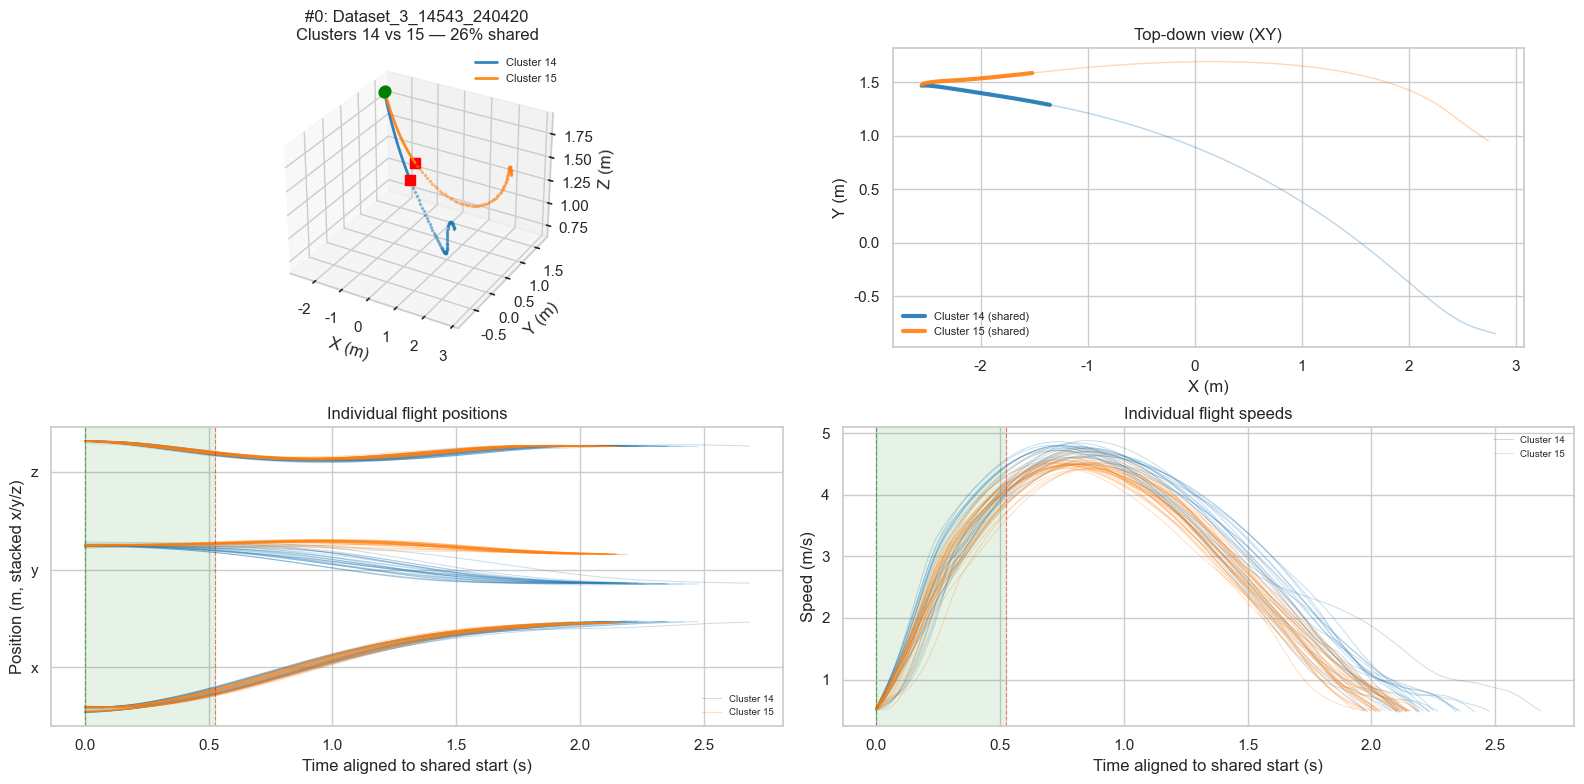


#1: Dataset_3_14543_240420, clusters 3 vs 4, overlap=27%, th=0.9m, flights=25+30, score=27.8


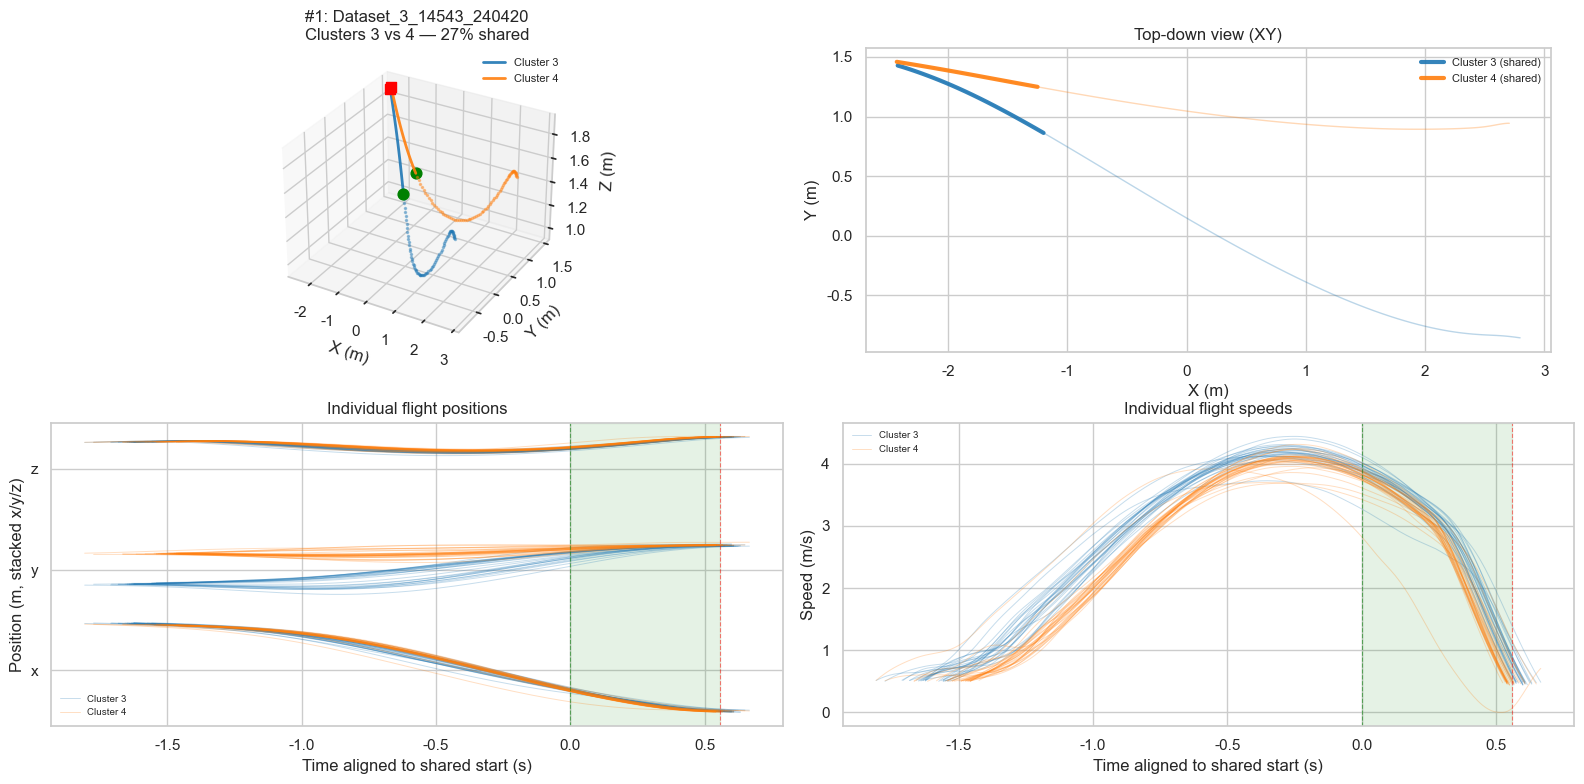


#2: Dataset_1_32622_231009, clusters 9 vs 16, overlap=32%, th=0.3m, flights=6+19, score=20.0


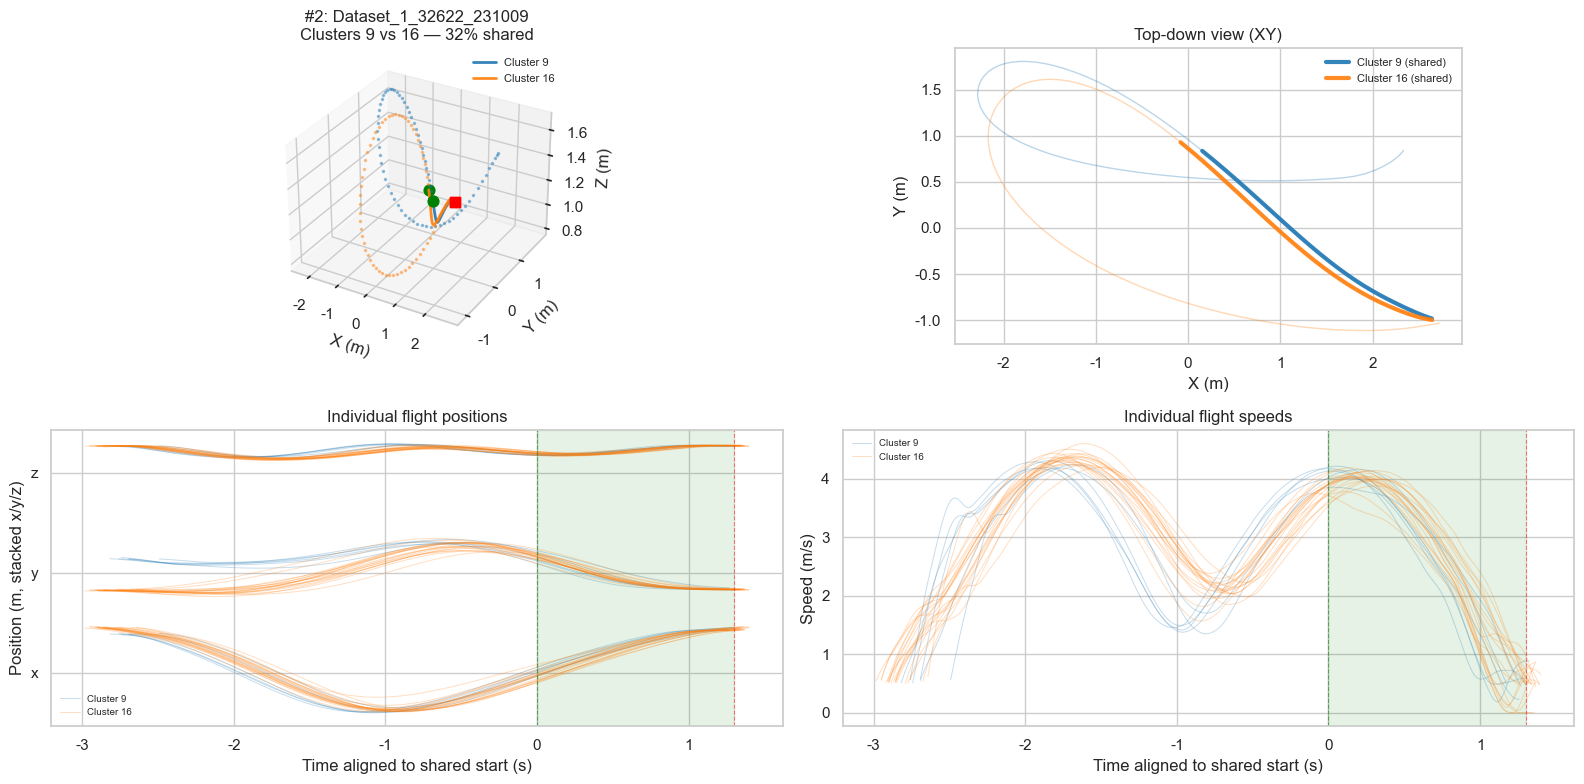


#3: Dataset_1_32622_231009, clusters 13 vs 16, overlap=48%, th=0.9m, flights=11+19, score=12.2


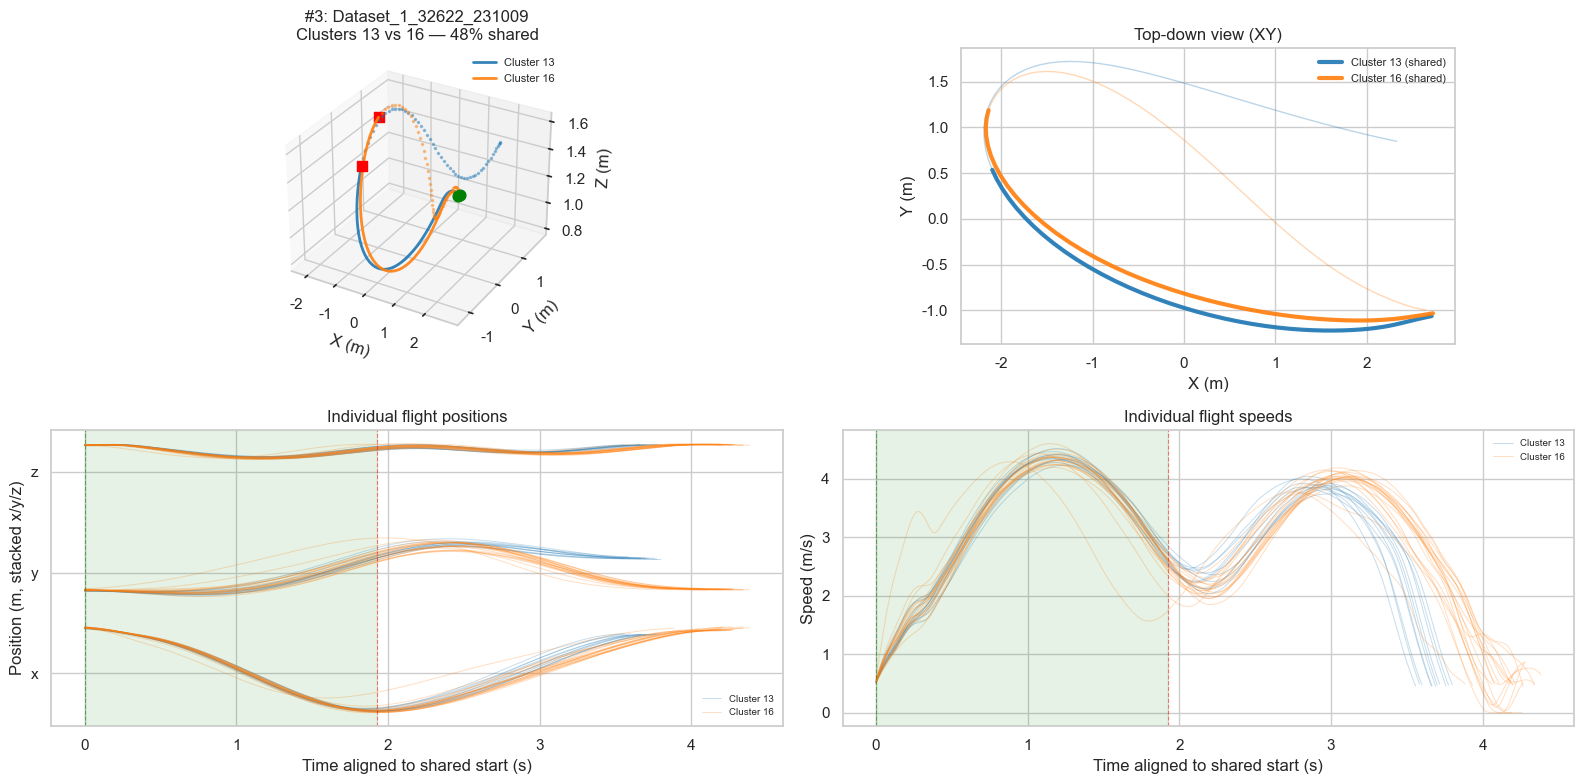


#4: Dataset_3_29959_240402, clusters 9 vs 14, overlap=25%, th=0.8m, flights=9+19, score=11.2


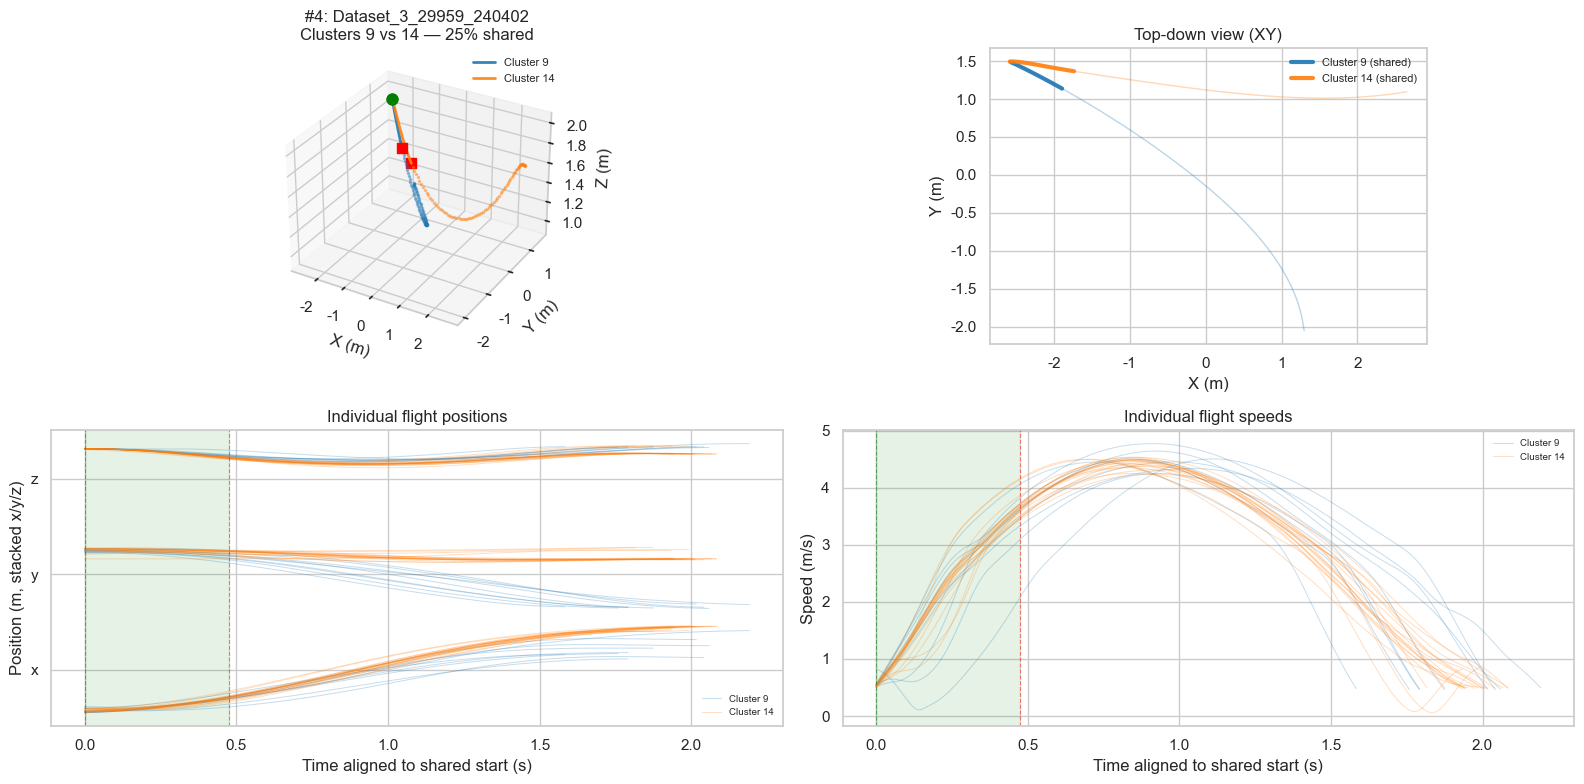


#5: Dataset_3_14543_240421, clusters 2 vs 3, overlap=62%, th=0.5m, flights=34+5, score=10.0


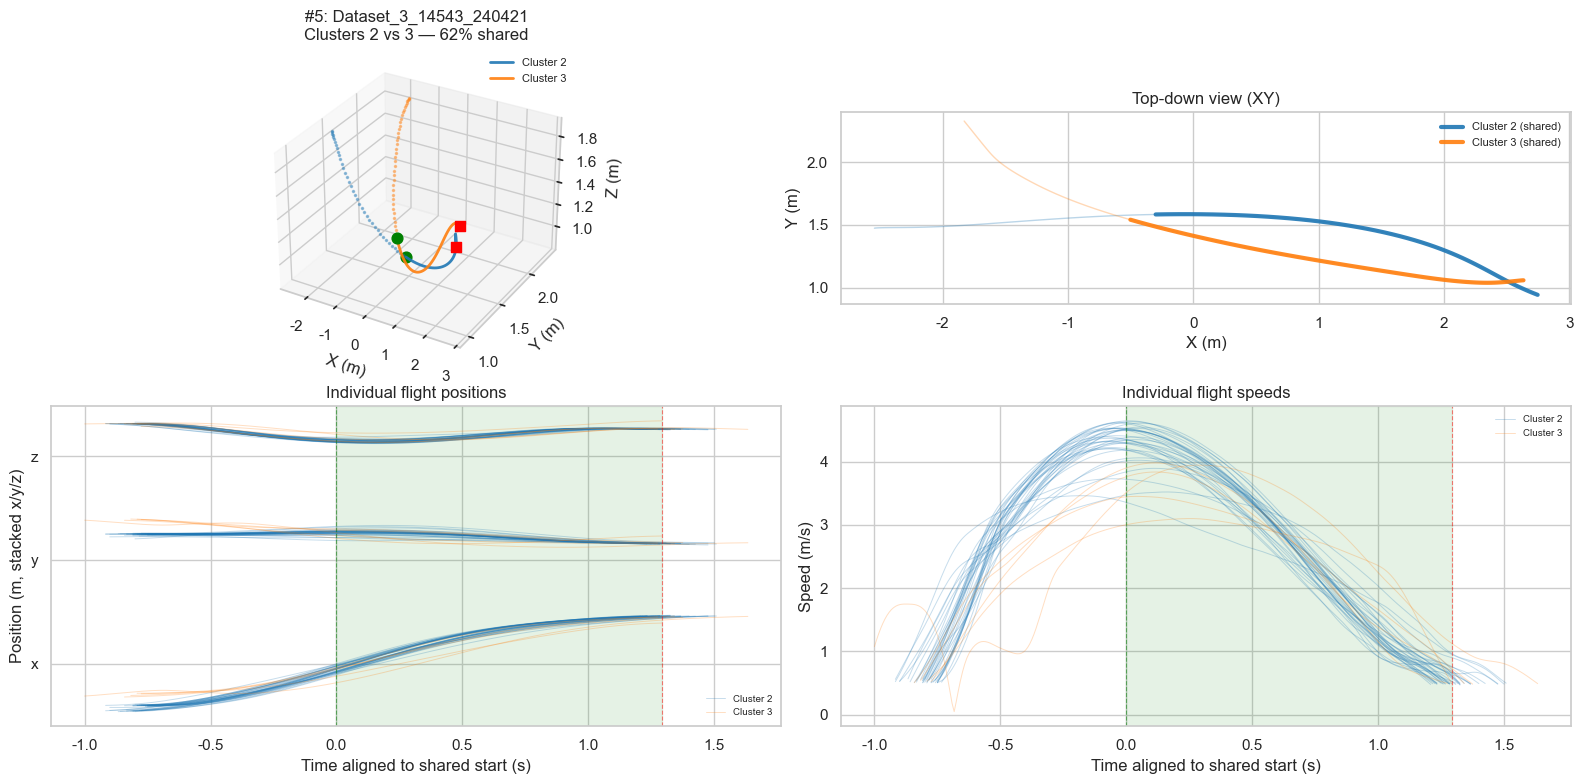


#6: Dataset_3_29959_240402, clusters 9 vs 10, overlap=28%, th=0.4m, flights=9+4, score=10.0


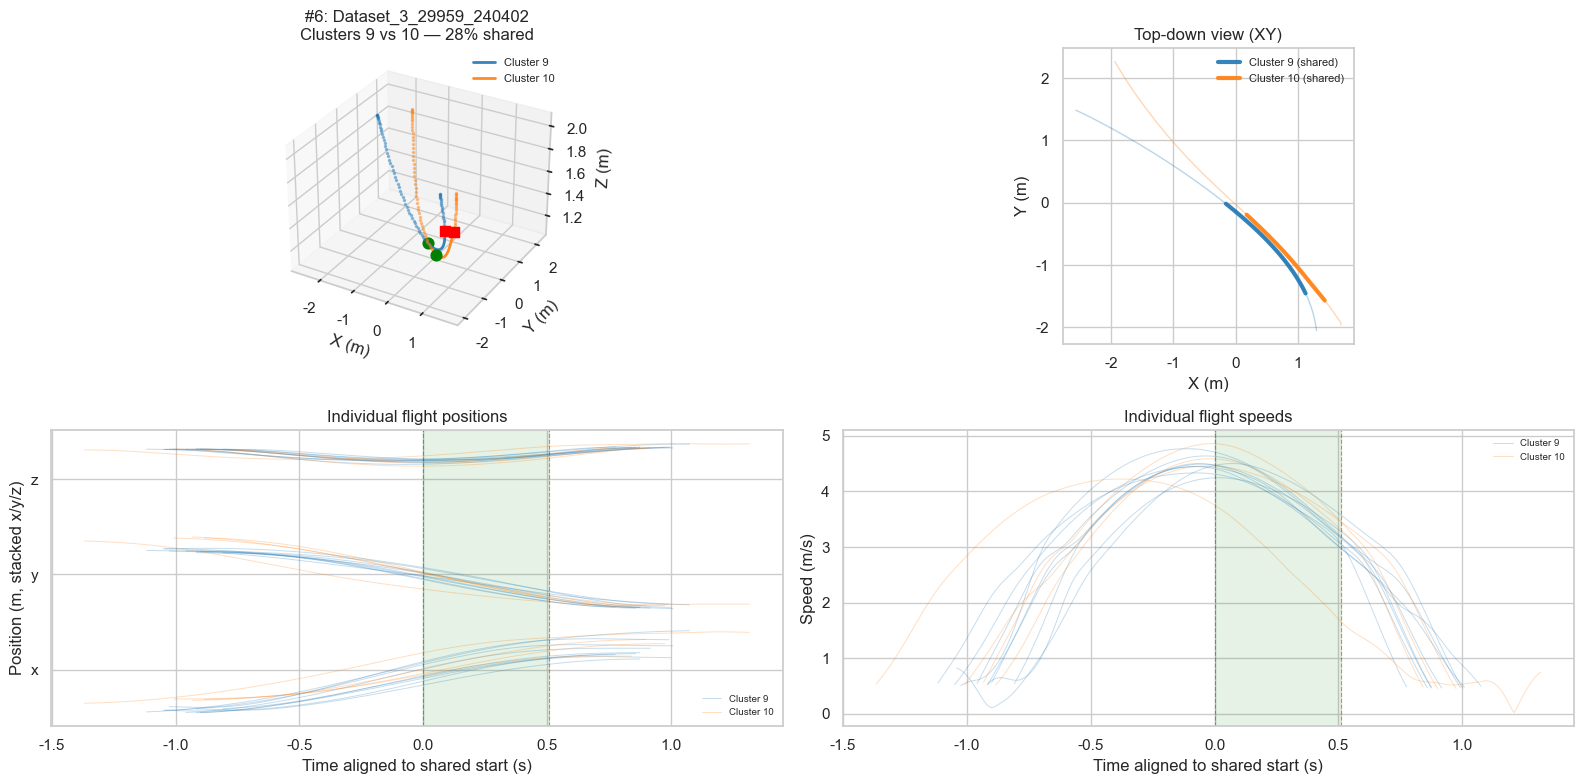


#7: Dataset_3_29959_240403, clusters 27 vs 28, overlap=50%, th=0.3m, flights=36+3, score=10.0


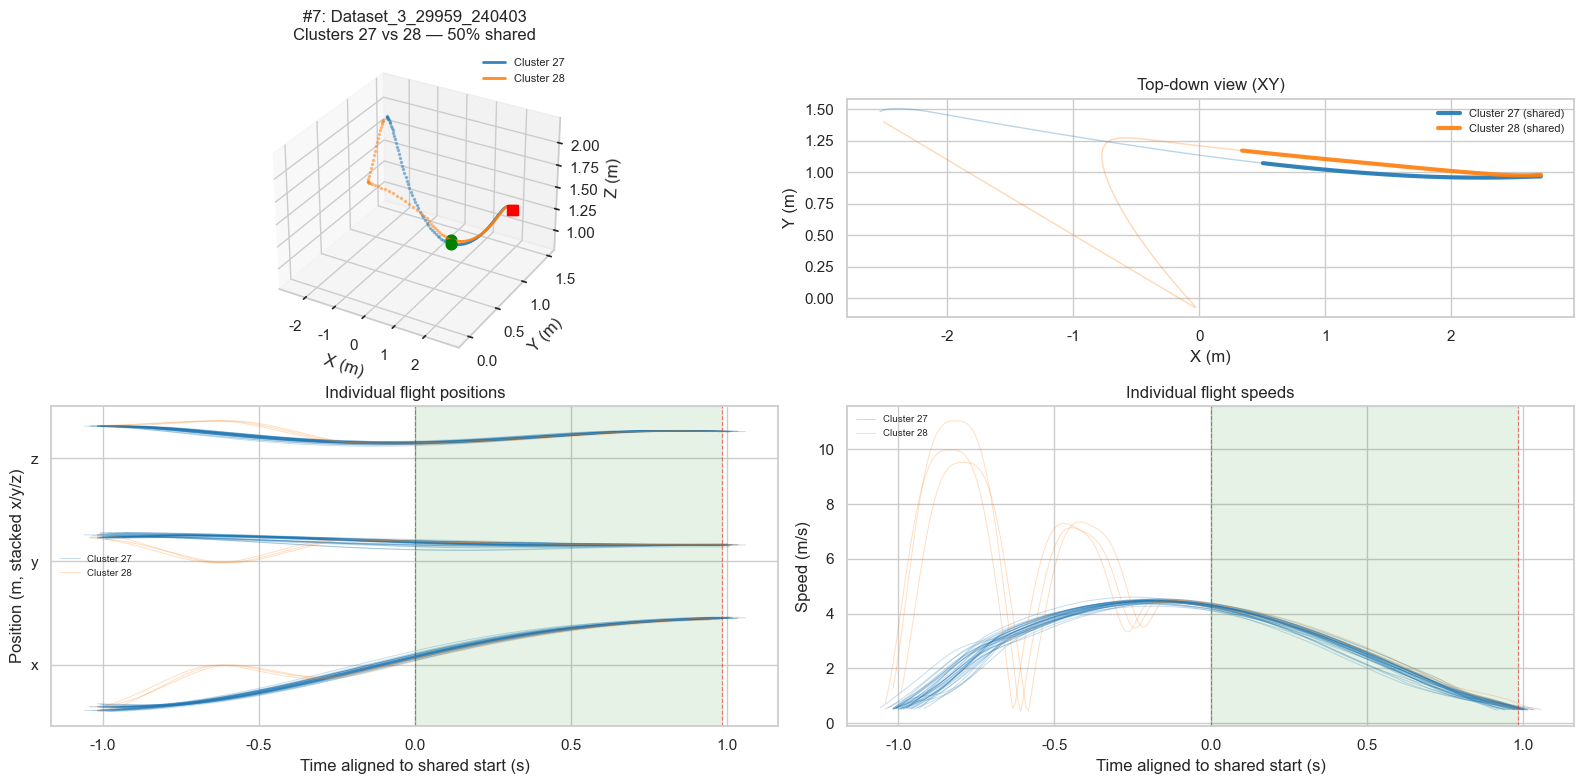


#8: Dataset_1_32622_231009, clusters 8 vs 13, overlap=27%, th=0.5m, flights=3+11, score=6.0


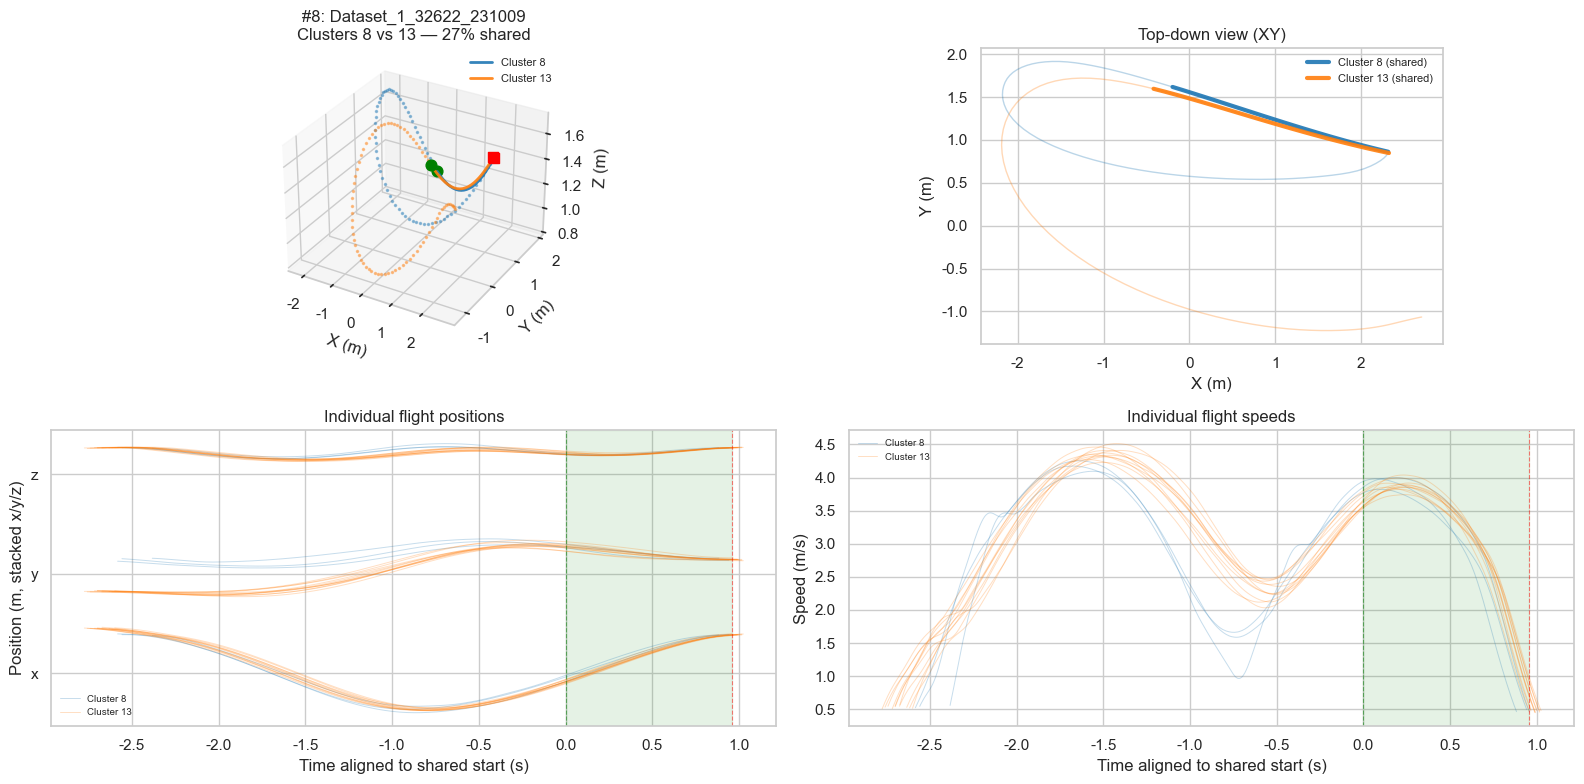


#9: Dataset_1_32622_231010, clusters 6 vs 10, overlap=26%, th=0.6m, flights=3+43, score=5.0


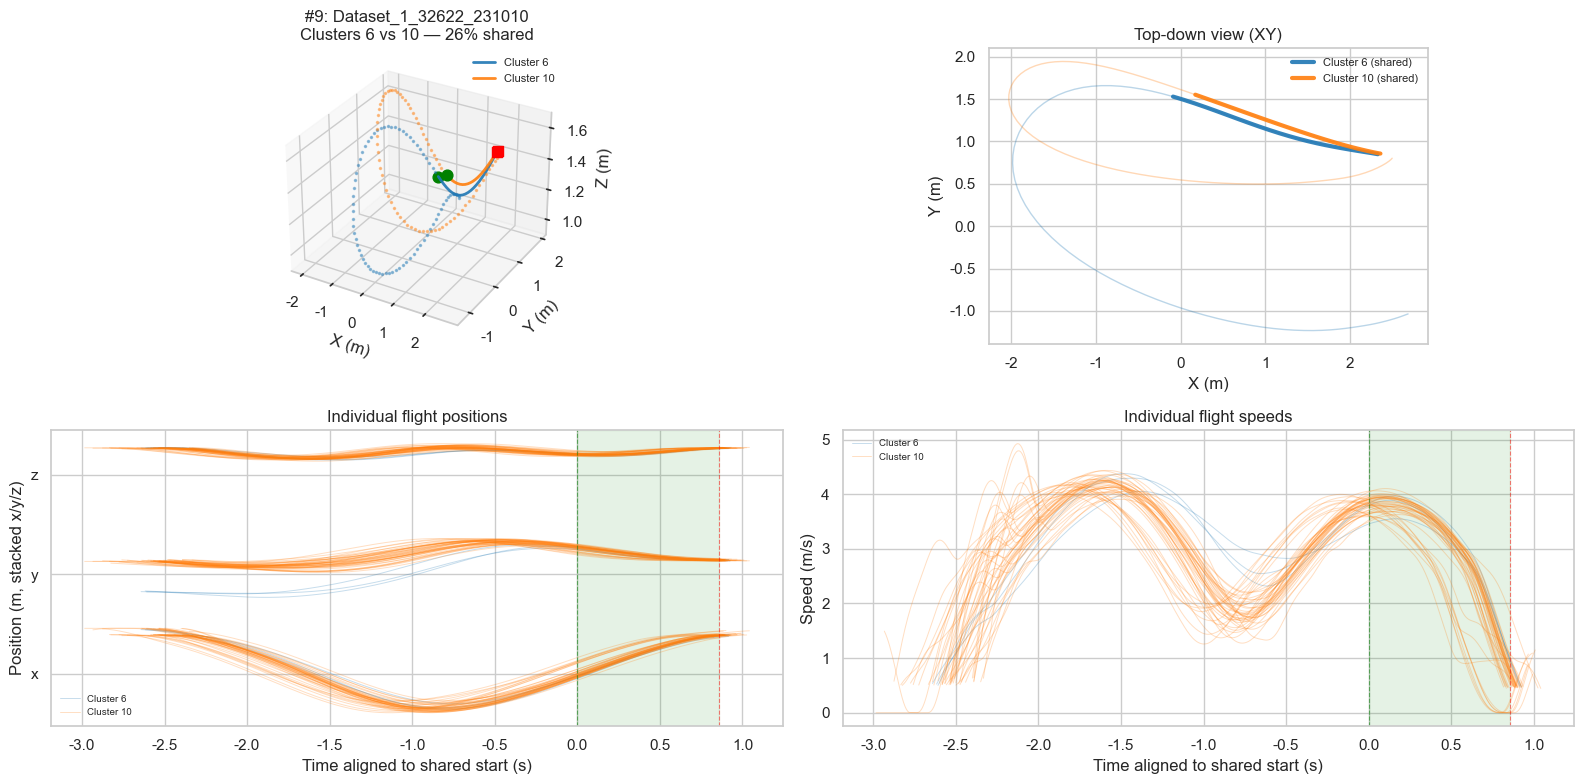

In [172]:
# --- Loop over top 10 candidates, visualize each ---
pal = sns.color_palette('tab10')
df_all_cand = pd.DataFrame(all_candidates).sort_values('attractiveness', ascending=False).reset_index(drop=True)

for SELECTED_IDX in range(min(10, len(df_all_cand))):
    sel = df_all_cand.iloc[SELECTED_IDX]
    session_name = sel['session']
    DIST_THRESHOLD = sel['threshold']
    ca, cb = int(sel['cluster_a']), int(sel['cluster_b'])

    # Unpack cached session data
    cached = session_data_cache[session_name]
    data = cached['data']
    r, t, Fs, v = data['r'], data['t'], data['Fs'], data['v']
    spike_times, pType = data['spike_times'], data['pType']
    df_flights = cached['df_flights']
    cluster_info = cached['cluster_info']
    df_clusters = pd.DataFrame([
        dict(cluster_id=cid, **{k: v for k, v in info.items()})
        for cid, info in cluster_info.items()
    ])

    s_start, s_end = int(sel['shared_start']), int(sel['shared_end'])
    traj_a, traj_b = sel['mean_traj_a'], sel['mean_traj_b']
    lf_pos, lf_vel = sel['local_frechet_pos'], sel['local_frechet_vel']

    print(f'\n#{SELECTED_IDX}: {session_name}, clusters {ca} vs {cb}, '
          f'overlap={sel["overlap_frac"]:.0%}, th={DIST_THRESHOLD:.1f}m, '
          f'flights={sel["n_flights_a"]}+{sel["n_flights_b"]}, '
          f'score={sel["attractiveness"]:.1f}')

    fig = plt.figure(figsize=(16, 8))

    # --- 3D trajectory plot ---
    ax3d = fig.add_subplot(2, 2, 1, projection='3d')
    frac = np.linspace(0, 1, N_DS)
    shared = np.zeros(N_DS, dtype=bool)
    shared[s_start:s_end + 1] = True

    for traj, color, label in [(traj_a, pal[0], f'Cluster {ca}'),
                                (traj_b, pal[1], f'Cluster {cb}')]:
        ax3d.plot(traj[~shared, 0], traj[~shared, 1], traj[~shared, 2],
                  '.', color=color, alpha=0.4, markersize=3)
        ax3d.plot(traj[shared, 0], traj[shared, 1], traj[shared, 2],
                  '-', color=color, alpha=0.9, linewidth=2, label=label)

    for traj in [traj_a, traj_b]:
        ax3d.scatter(*traj[s_start], color='green', s=60, zorder=5, marker='o')
        ax3d.scatter(*traj[s_end], color='red', s=60, zorder=5, marker='s')

    ax3d.set_xlabel('X (m)')
    ax3d.set_ylabel('Y (m)')
    ax3d.set_zlabel('Z (m)')
    ax3d.set_title(f'#{SELECTED_IDX}: {session_name}\nClusters {ca} vs {cb} \u2014 {sel["overlap_frac"]:.0%} shared')
    ax3d.legend(fontsize=8)

    # --- 2D top-down view ---
    ax2d = fig.add_subplot(2, 2, 2)
    for traj, color, label in [(traj_a, pal[0], f'Cluster {ca}'),
                                (traj_b, pal[1], f'Cluster {cb}')]:
        ax2d.plot(traj[:, 0], traj[:, 1], '-', color=color, alpha=0.3, linewidth=1)
        ax2d.plot(traj[shared, 0], traj[shared, 1], '-', color=color, alpha=0.9,
                  linewidth=3, label=label + ' (shared)')
    ax2d.set_xlabel('X (m)')
    ax2d.set_ylabel('Y (m)')
    ax2d.set_title('Top-down view (XY)')
    ax2d.legend(fontsize=8)
    ax2d.set_aspect('equal')

    # --- Individual flight traces in real time, aligned to shared segment start ---

    ax_pos = fig.add_subplot(2, 2, 3)
    ax_spd = fig.add_subplot(2, 2, 4)
    dim_labels = ['x', 'y', 'z']

    for cid, color, clabel in [(ca, pal[0], f'Cluster {ca}'),
                                (cb, pal[1], f'Cluster {cb}')]:
        fl_grp = df_flights[df_flights['cluster_id'] == cid]
        for fi, (_, frow) in enumerate(fl_grp.iterrows()):
            fs, fe = int(frow['f_start']), int(frow['f_stop'])
            flight_r = r[fs:fe + 1]
            flight_v = v[fs:fe + 1]
            flight_t = t[fs:fe + 1]
            # Map shared segment start from downsampled index to real time index
            n_samp = fe - fs + 1
            real_start_idx = int(s_start / N_DS * n_samp)
            t0 = flight_t[real_start_idx]
            t_al = flight_t - t0
            # Position: stack x, y, z with offsets
            for dim, dl in enumerate(dim_labels):
                ax_pos.plot(t_al, flight_r[:, dim] + dim * 6,
                            color=color, alpha=0.25, linewidth=0.7,
                            label=clabel if fi == 0 and dim == 0 else None)
            # Speed
            speed = np.linalg.norm(flight_v, axis=1)
            ax_spd.plot(t_al, speed, color=color, alpha=0.25, linewidth=0.7,
                        label=clabel if fi == 0 else None)

    # Shade shared region using median shared duration
    sh_durs = []
    for cid in [ca, cb]:
        for _, frow in df_flights[df_flights['cluster_id'] == cid].iterrows():
            fs, fe = int(frow['f_start']), int(frow['f_stop'])
            fr = r[fs:fe + 1]
            ft = t[fs:fe + 1]
            n_samp_sh = fe - fs + 1
            rs = int(s_start / N_DS * n_samp_sh)
            re = int(s_end / N_DS * n_samp_sh)
            sh_durs.append(ft[re] - ft[rs])
    med_sh_dur = np.median(sh_durs)
    for ax in [ax_pos, ax_spd]:
        ax.axvspan(0, med_sh_dur, color='green', alpha=0.1)
        ax.axvline(0, color='green', ls='--', lw=0.8, alpha=0.5)
        ax.axvline(med_sh_dur, color='red', ls='--', lw=0.8, alpha=0.5)

    ax_pos.set_xlabel('Time aligned to shared start (s)')
    ax_pos.set_ylabel('Position (m, stacked x/y/z)')
    ax_pos.set_title('Individual flight positions')
    ax_pos.legend(fontsize=7)
    ax_pos.set_yticks([0, 6, 12])
    ax_pos.set_yticklabels(['x', 'y', 'z'])

    ax_spd.set_xlabel('Time aligned to shared start (s)')
    ax_spd.set_ylabel('Speed (m/s)')
    ax_spd.set_title('Individual flight speeds')
    ax_spd.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

# After loop, sel/session_name/ca/cb/etc. are set to the LAST candidate shown.
# To pick a specific one for downstream analysis, set SELECTED_IDX below.


In [177]:
# --- Pick one candidate for downstream alignment/raster/stats ---
SELECTED_IDX = 8  # <-- change to pick a different candidate from above

sel = df_all_cand.iloc[SELECTED_IDX]
session_name = sel['session']
DIST_THRESHOLD = sel['threshold']
ca, cb = int(sel['cluster_a']), int(sel['cluster_b'])

cached = session_data_cache[session_name]
data = cached['data']
r, t, Fs, v = data['r'], data['t'], data['Fs'], data['v']
spike_times, pType = data['spike_times'], data['pType']
df_flights = cached['df_flights']
cluster_info = cached['cluster_info']
df_clusters = pd.DataFrame([
    dict(cluster_id=cid, **{k: v for k, v in info.items()})
    for cid, info in cluster_info.items()
])

print(f'Selected: {session_name}, clusters {ca} vs {cb}')
print(f'  Overlap: {sel["overlap_frac"]:.0%}, threshold: {DIST_THRESHOLD:.1f}m')
print(f'  Flights: {sel["n_flights_a"]} + {sel["n_flights_b"]}')
print(f'  Attractiveness score: {sel["attractiveness"]:.1f}')


Selected: Dataset_1_32622_231009, clusters 8 vs 13
  Overlap: 27%, threshold: 0.5m
  Flights: 3 + 11
  Attractiveness score: 6.0


## Align Individual Flights to Shared Segment

In [178]:
# Map shared segment from downsampled indices to real time per flight
s_start_ds, s_end_ds = int(sel['shared_start']), int(sel['shared_end'])
print(f"Aligning clusters {ca} vs {cb}, shared segment ds indices [{s_start_ds}, {s_end_ds}]")

# For each flight in both clusters, find the raw time index of the shared segment
aligned_flights = []
for _, frow in df_flights[df_flights['cluster_id'].isin([ca, cb])].iterrows():
    f_start, f_stop = int(frow['f_start']), int(frow['f_stop'])
    flight_r = r[f_start:f_stop + 1]  # (T, 3)
    flight_v = v[f_start:f_stop + 1]  # (T, 3)
    flight_t = t[f_start:f_stop + 1]  # (T,)

    # Map shared segment boundaries from downsampled index to real time index.
    # downsample_trajectory interpolates uniformly in sample index (= time),
    # so index k in N_DS space maps to int(k/N_DS * n_samples) in real space.
    n_samp = f_stop - f_start + 1
    shared_start_idx = int(s_start_ds / N_DS * n_samp)
    shared_end_idx = int(s_end_ds / N_DS * n_samp)

    # Time of shared segment start (for alignment)
    t_shared_start = flight_t[shared_start_idx]

    # Aligned time: t=0 at shared segment start
    t_aligned = flight_t - t_shared_start

    # Shared mask
    shared_mask = np.zeros(len(flight_t), dtype=bool)
    shared_mask[shared_start_idx:shared_end_idx + 1] = True

    # Align spike times: t=0 at shared segment start
    t_flight_start = flight_t[0]
    t_flight_end = flight_t[-1]
    flight_spikes = []
    for unit_spk in spike_times:
        mask = (unit_spk >= t_flight_start) & (unit_spk <= t_flight_end)
        flight_spikes.append(unit_spk[mask] - t_shared_start)

    aligned_flights.append(dict(
        cluster_id=frow['cluster_id'],
        flight_idx=frow['flight_idx'],
        f_start=f_start,
        f_stop=f_stop,
        t_aligned=t_aligned,
        t_abs=flight_t,
        r=flight_r,
        v=flight_v,
        shared_mask=shared_mask,
        shared_start_idx=shared_start_idx,
        shared_end_idx=shared_end_idx,
        t_shared_start=t_shared_start,
        t_shared_end=flight_t[shared_end_idx],
        shared_dur=flight_t[shared_end_idx] - t_shared_start,
        spikes_aligned=flight_spikes,
    ))

df_aligned = pd.DataFrame(aligned_flights)
print(f"\n{len(df_aligned)} aligned flights:")
print(df_aligned.groupby('cluster_id')[['shared_dur']].describe().round(3))


Aligning clusters 8 vs 13, shared segment ds indices [73, 99]

14 aligned flights:
           shared_dur                                                 
                count   mean    std    min    25%    50%    75%    max
cluster_id                                                            
8.0               3.0  0.897  0.035  0.858  0.883  0.908  0.917  0.925
13.0             11.0  0.960  0.022  0.925  0.945  0.958  0.975  0.992


## Raster Plots with Position Traces

In [179]:
# Select top 10 units by bin-wise PSTH difference in shared segment.
# For each unit, compute smoothed PSTH per cluster in the shared window,
# then sum |PSTH_a - PSTH_b| / mean_rate across bins. This captures
# temporally localized differences, not just overall rate changes.
from scipy.ndimage import gaussian_filter1d

n_units = len(spike_times)
flights_a_sel = df_aligned[df_aligned['cluster_id'] == ca]
flights_b_sel = df_aligned[df_aligned['cluster_id'] == cb]
median_sh_dur = df_aligned['shared_dur'].median()

PSTH_BIN = 0.050  # 50 ms bins
PSTH_SIGMA = 0.030  # 30 ms smoothing
sigma_bins = PSTH_SIGMA / PSTH_BIN

# Shared segment bins
sh_edges = np.arange(0, median_sh_dur + PSTH_BIN, PSTH_BIN)
n_bins = len(sh_edges) - 1

psth_diff_score = np.full(n_units, np.nan)
for u in range(n_units):
    # Compute smoothed PSTH per flight, then average per cluster
    psths = {}
    for label, flights in [('a', flights_a_sel), ('b', flights_b_sel)]:
        trial_psths = []
        for _, row in flights.iterrows():
            spk = row['spikes_aligned'][u]
            counts, _ = np.histogram(spk, bins=sh_edges)
            rate = counts / PSTH_BIN
            trial_psths.append(gaussian_filter1d(rate.astype(float), sigma_bins))
        psths[label] = np.mean(trial_psths, axis=0)  # (n_bins,)

    mean_rate = (psths['a'].mean() + psths['b'].mean()) / 2
    if mean_rate > 1.0:  # require > 1 Hz to avoid noise
        # Sum of absolute bin-wise differences, normalized by mean rate
        psth_diff_score[u] = np.sum(np.abs(psths['a'] - psths['b'])) / (mean_rate * n_bins)

# Top 10 by normalized bin-wise difference
valid_units = np.where(~np.isnan(psth_diff_score))[0]
top_units = valid_units[np.argsort(psth_diff_score[valid_units])[::-1][:10]]
print(f'Top 10 units by bin-wise PSTH difference (shared segment):')
for u in top_units:
    print(f'  Unit {u} (pType: {str(pType[u])}): '
          f'score={psth_diff_score[u]:.3f}')


Top 10 units by bin-wise PSTH difference (shared segment):
  Unit 73 (pType: pPYR): score=1.933
  Unit 84 (pType: pPYR): score=1.877
  Unit 35 (pType: pPYR): score=1.551
  Unit 93 (pType: pPYR): score=1.185
  Unit 28 (pType: pPYR): score=1.177
  Unit 29 (pType: pPYR): score=1.082
  Unit 9 (pType: []): score=1.075
  Unit 36 (pType: pPYR): score=1.059
  Unit 69 (pType: pPYR): score=0.995
  Unit 4 (pType: pPYR): score=0.938


/tmp/ipykernel_595051/290128774.py:83: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(interped, axis=0)
/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_595051/290128774.py:101: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(interped, axis=0)


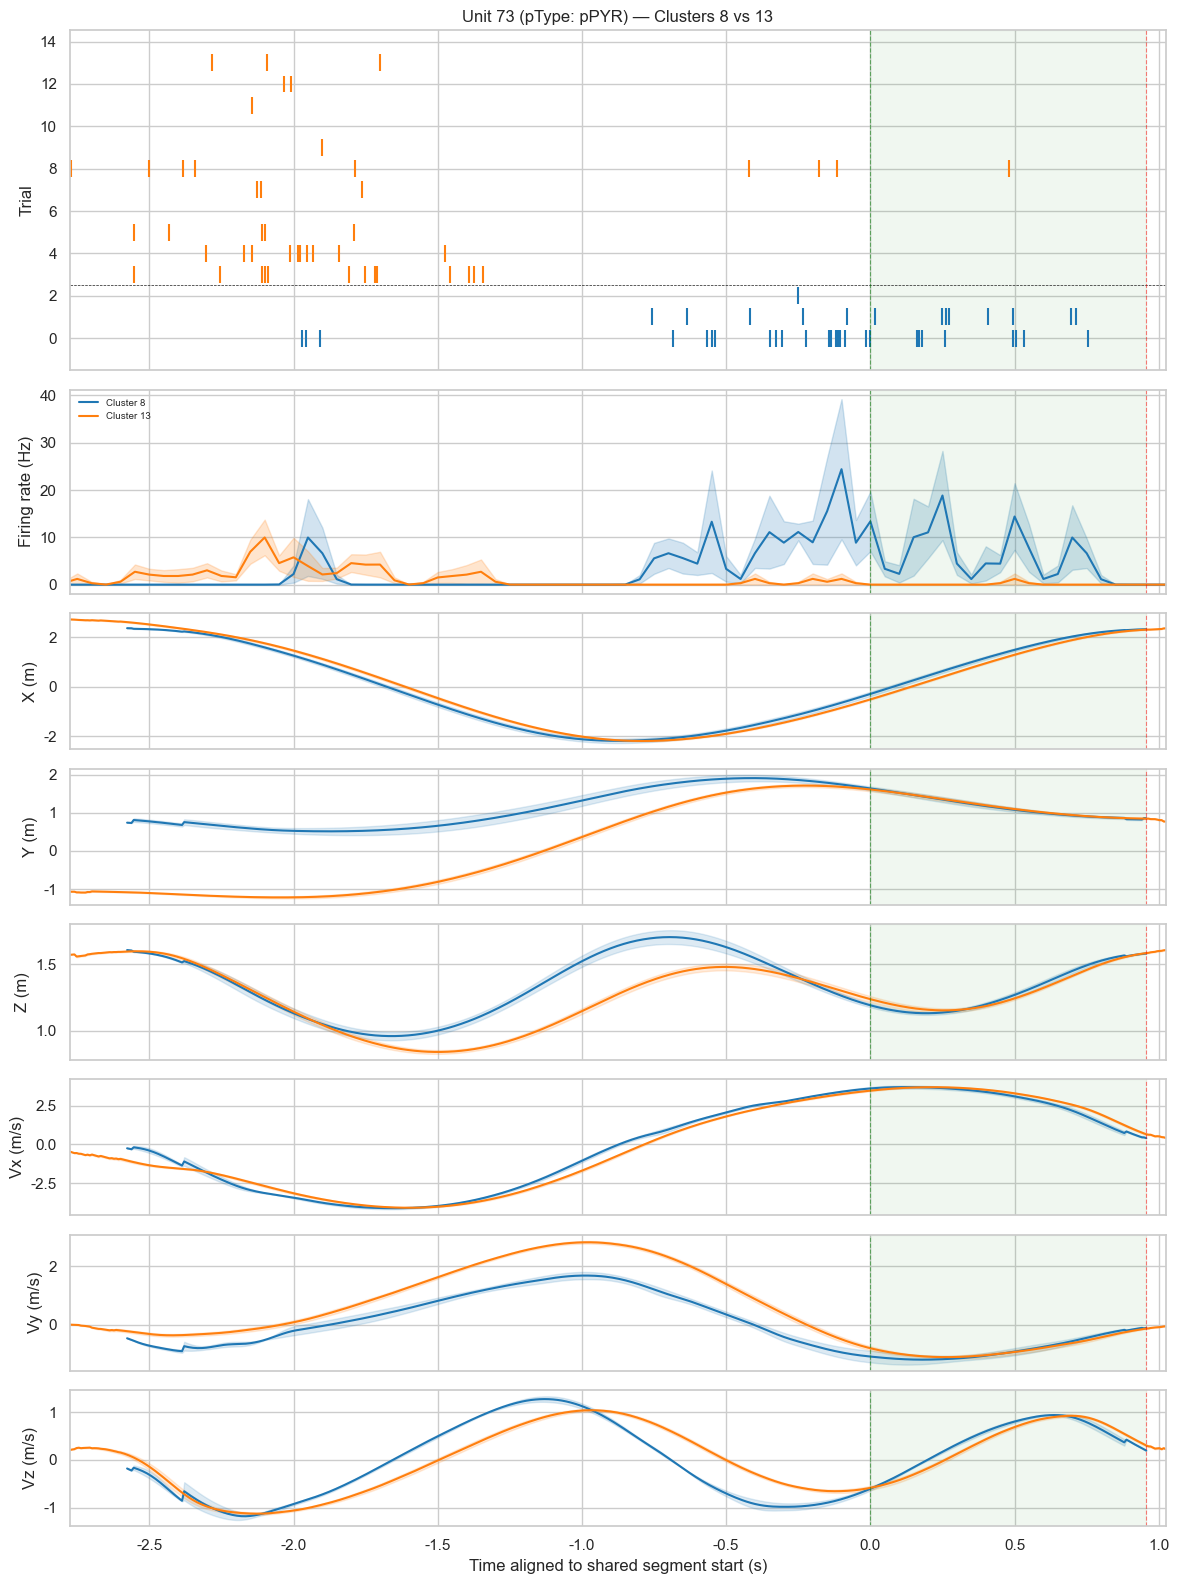

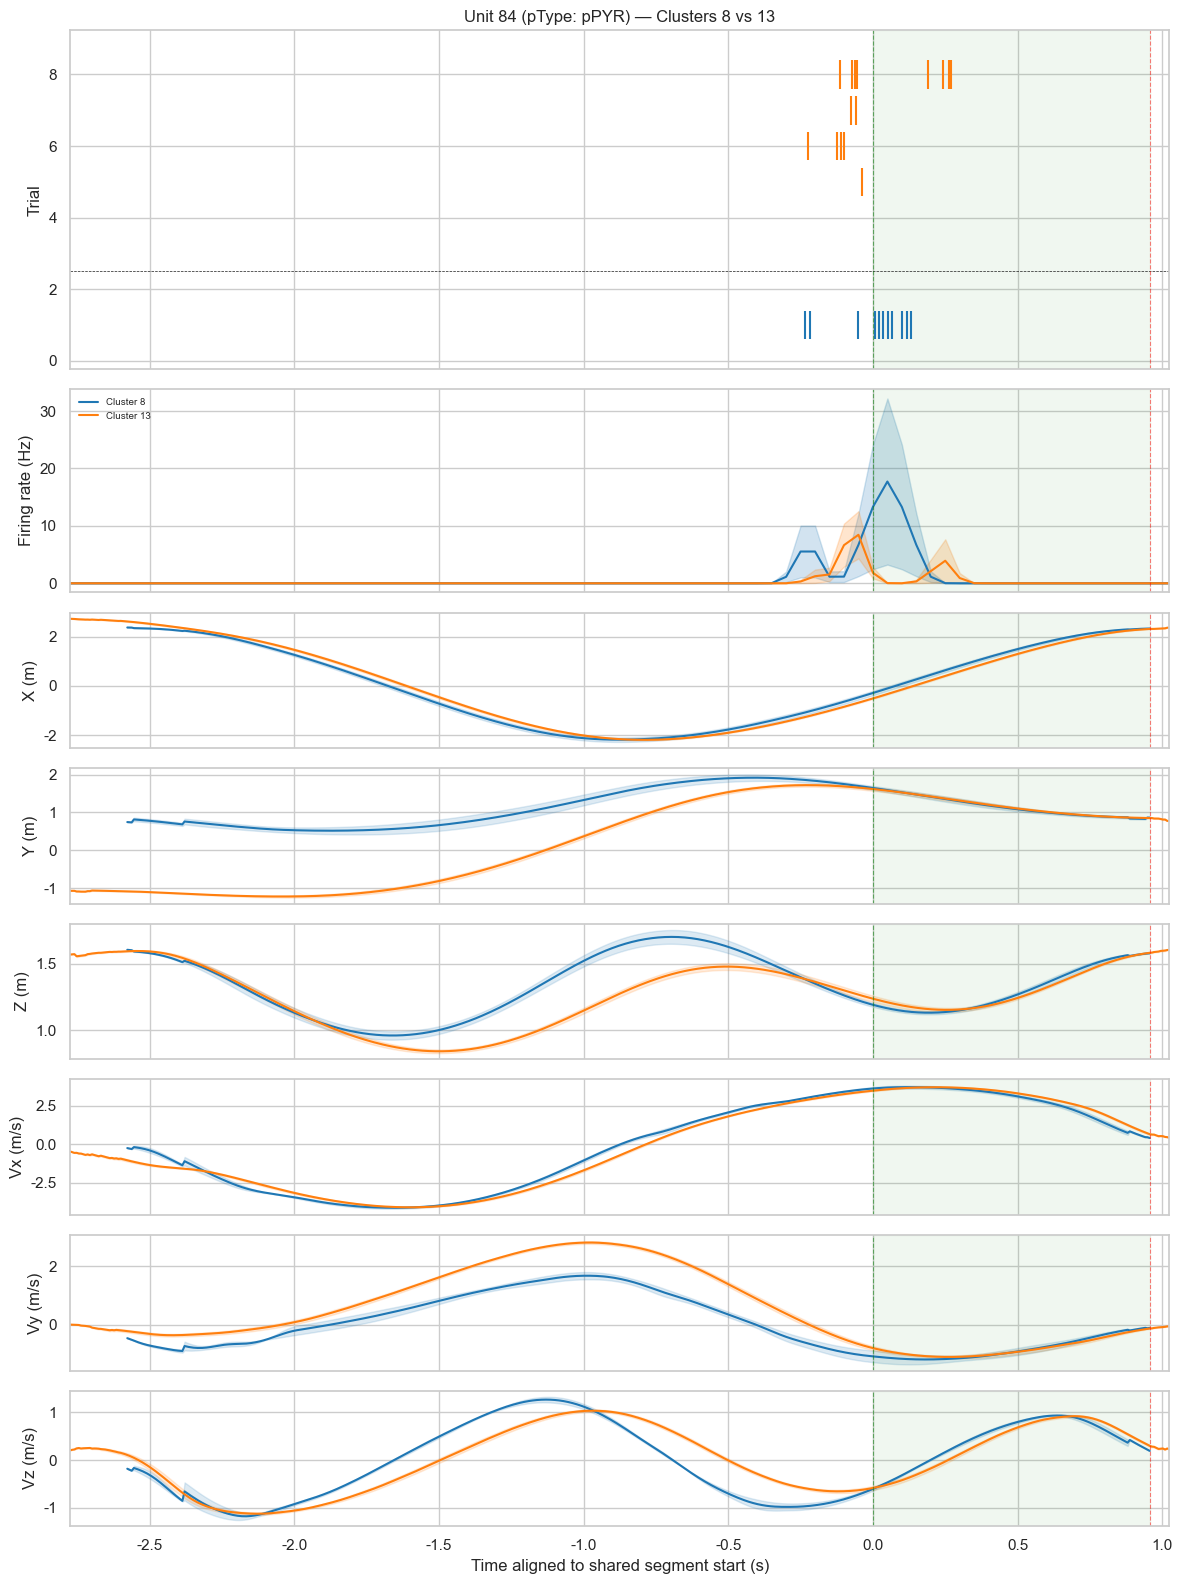

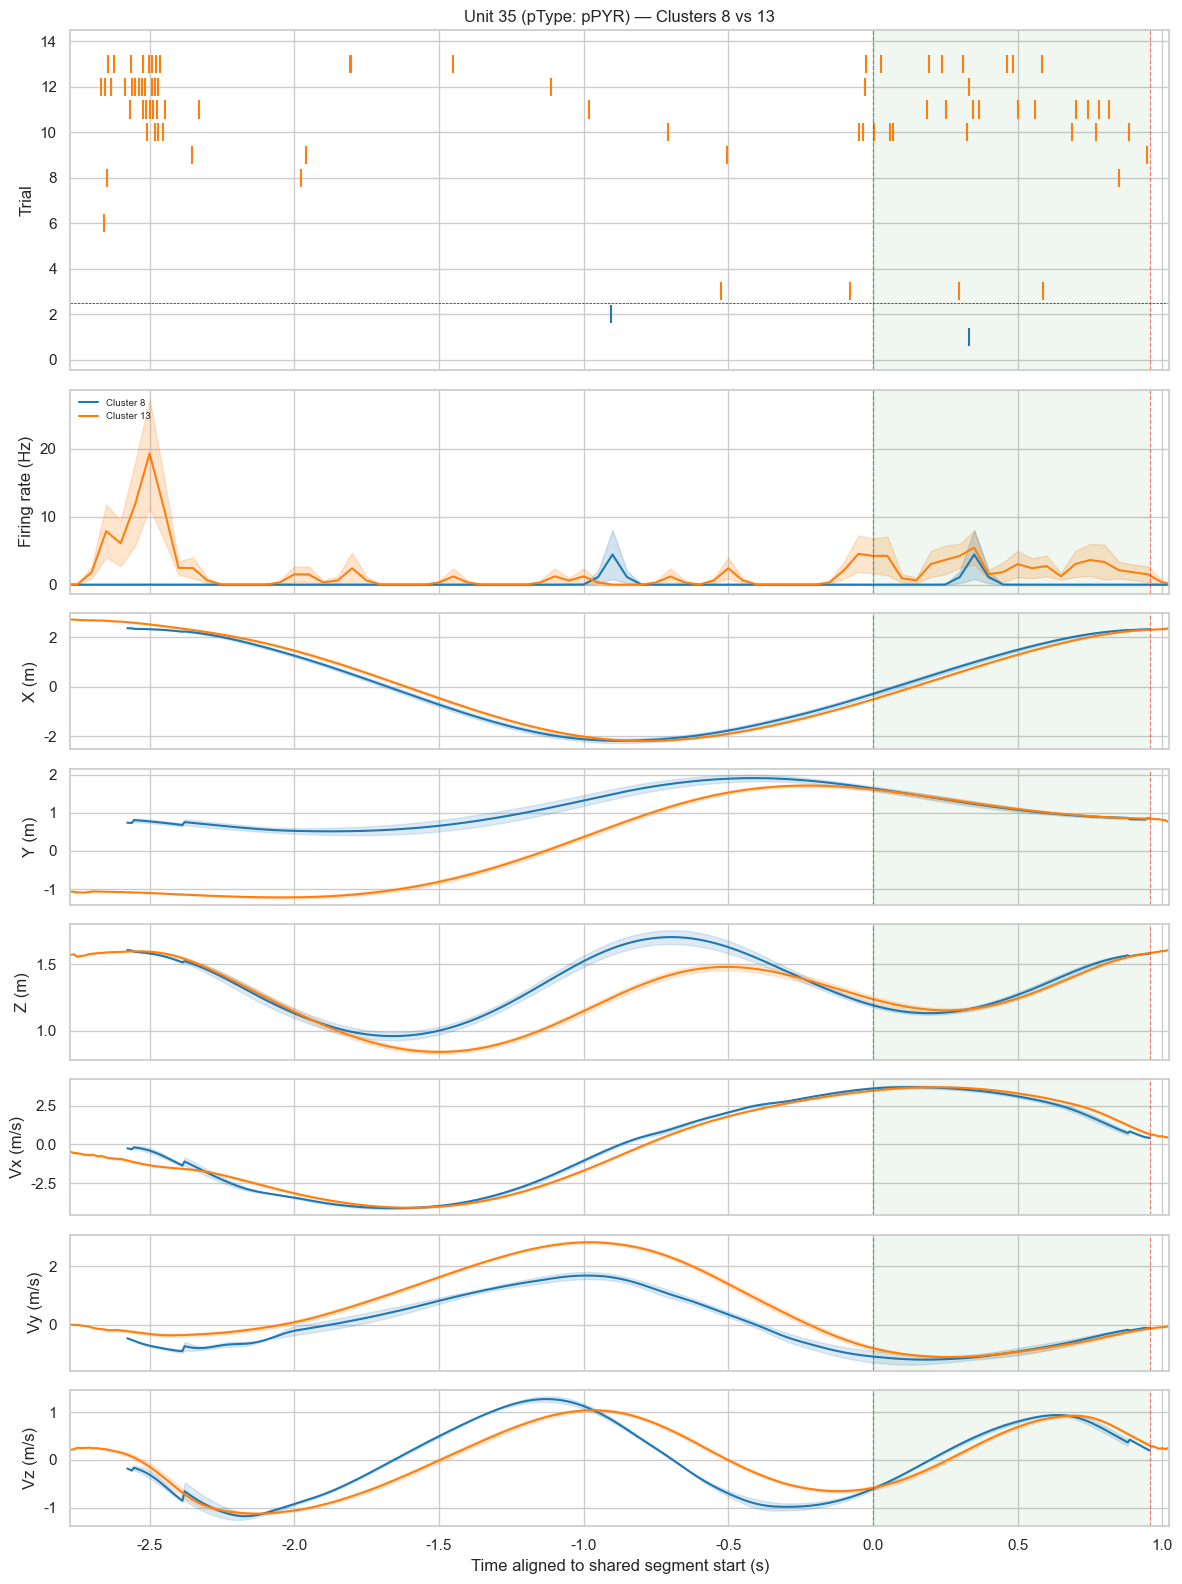

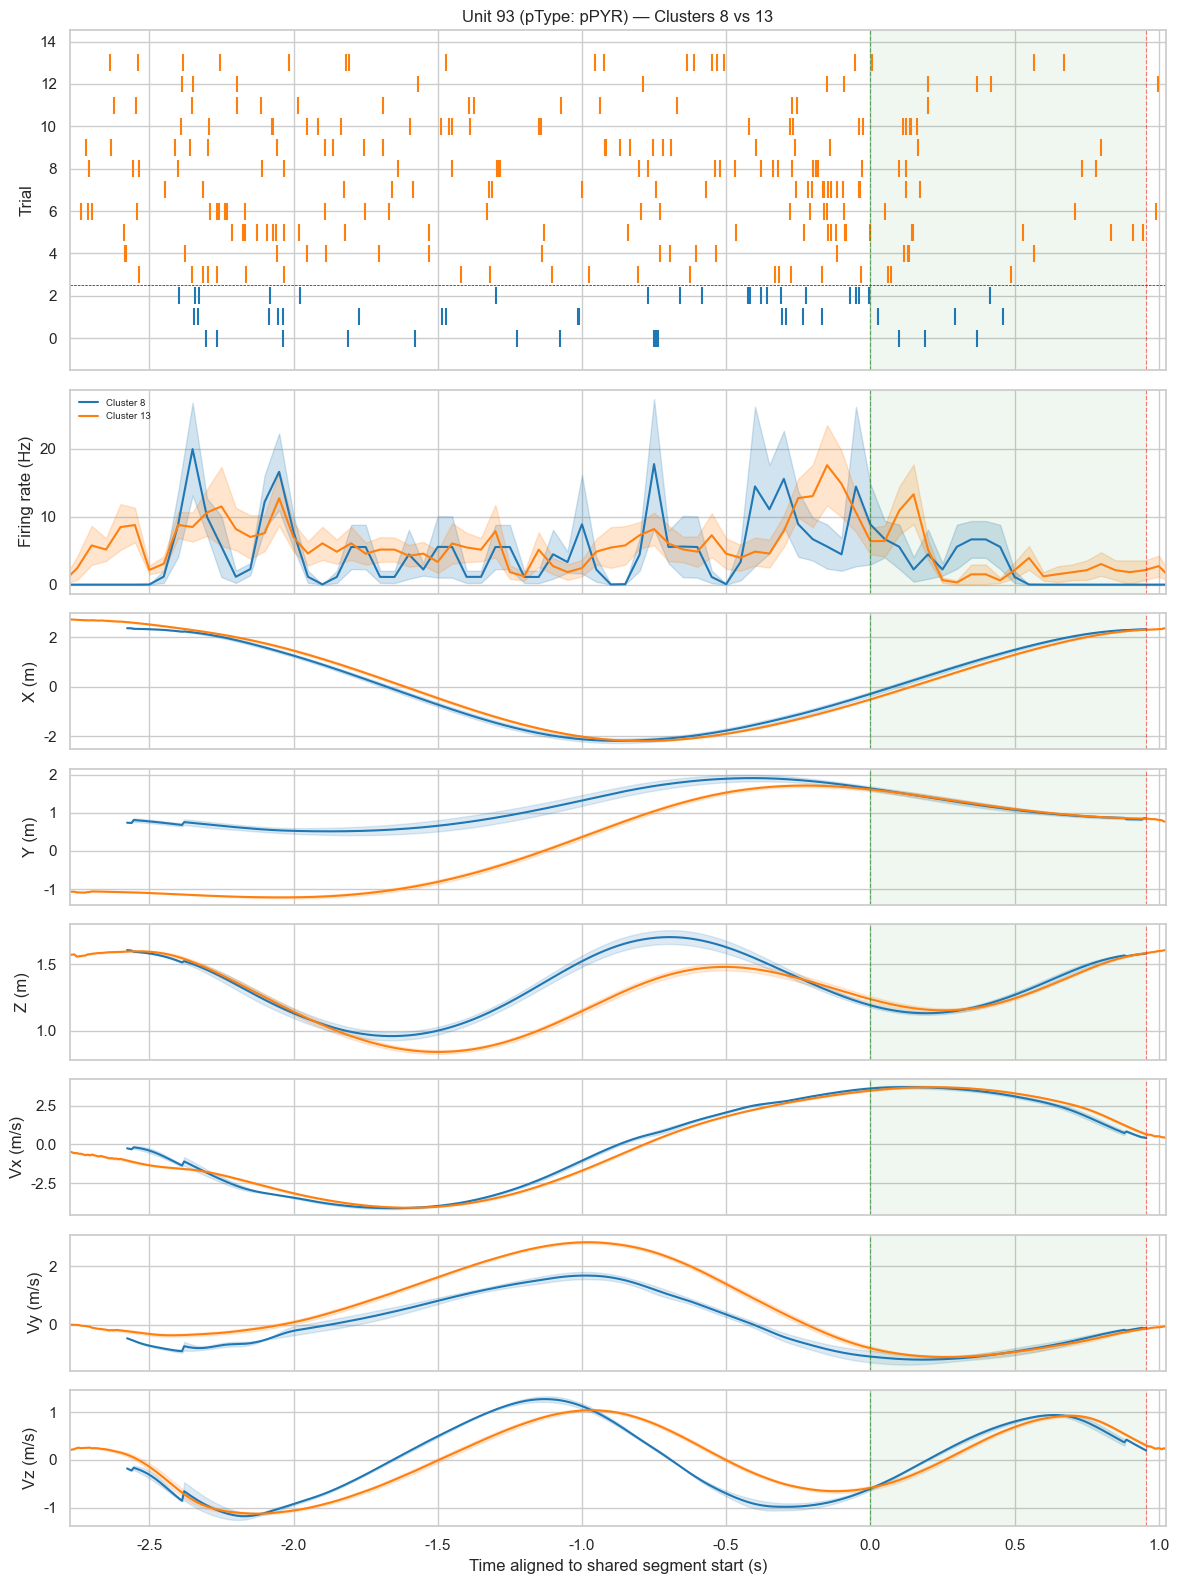

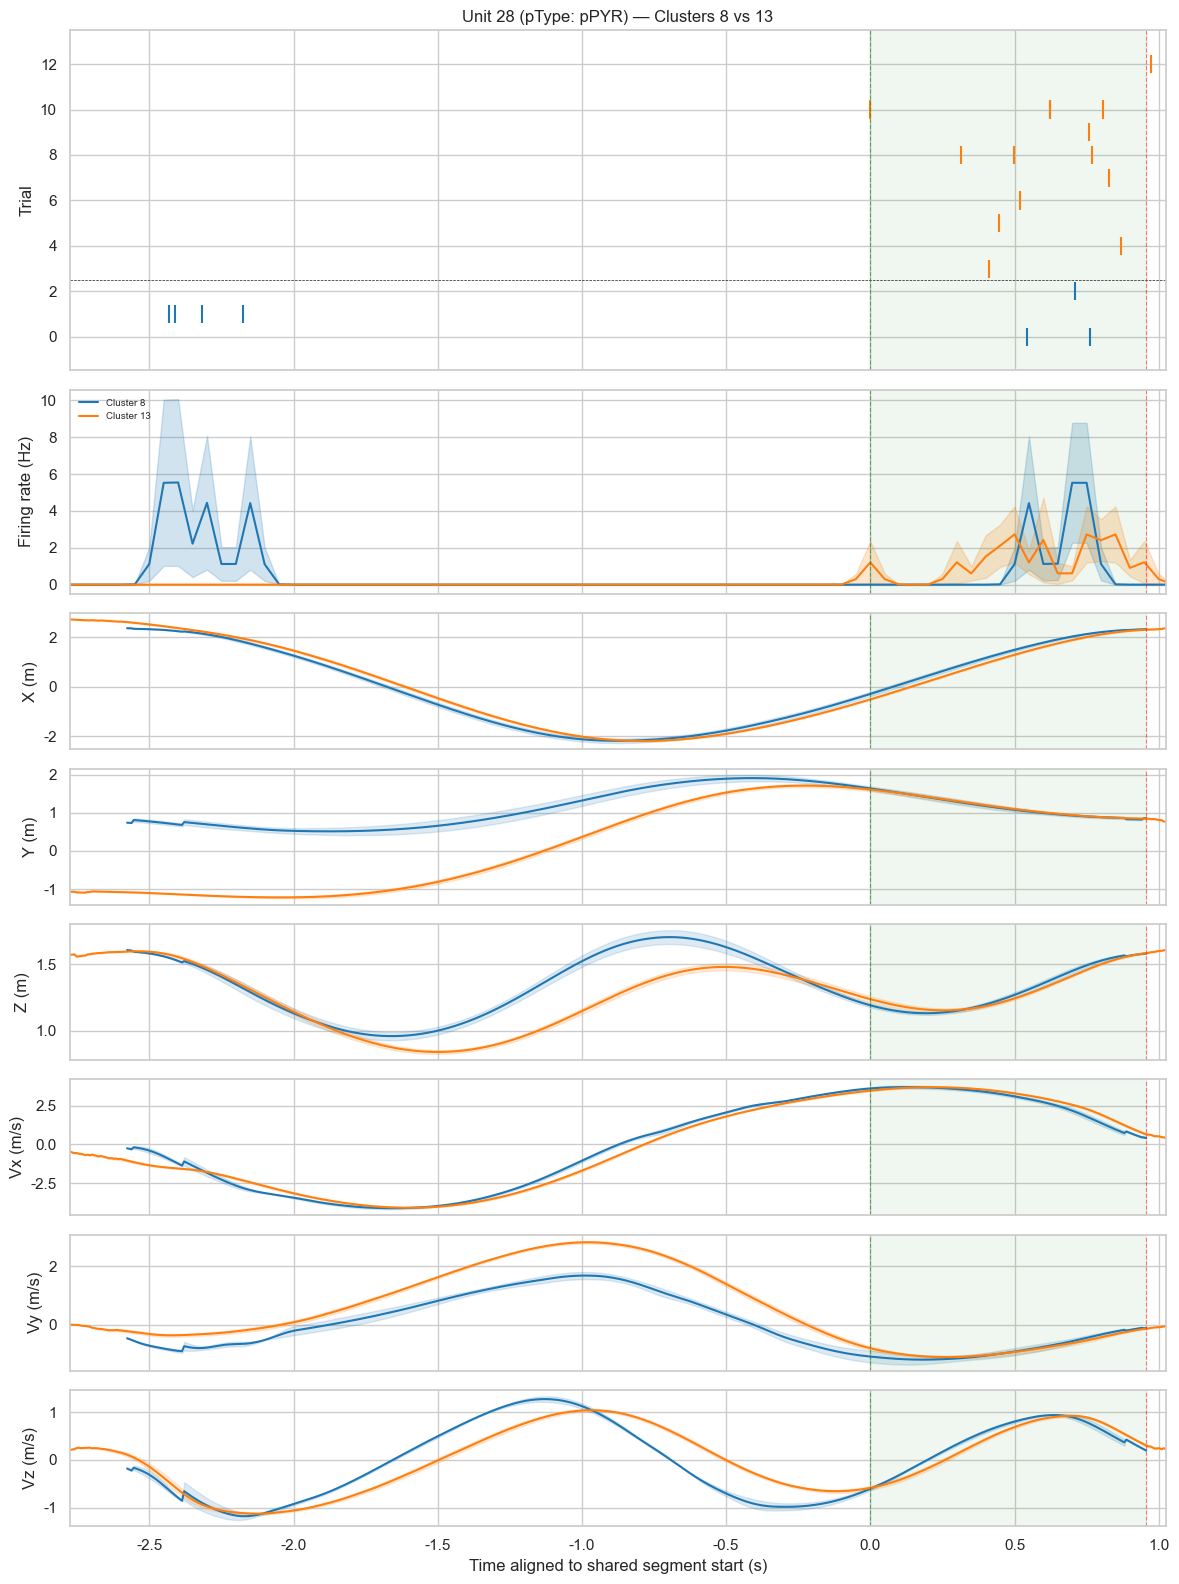

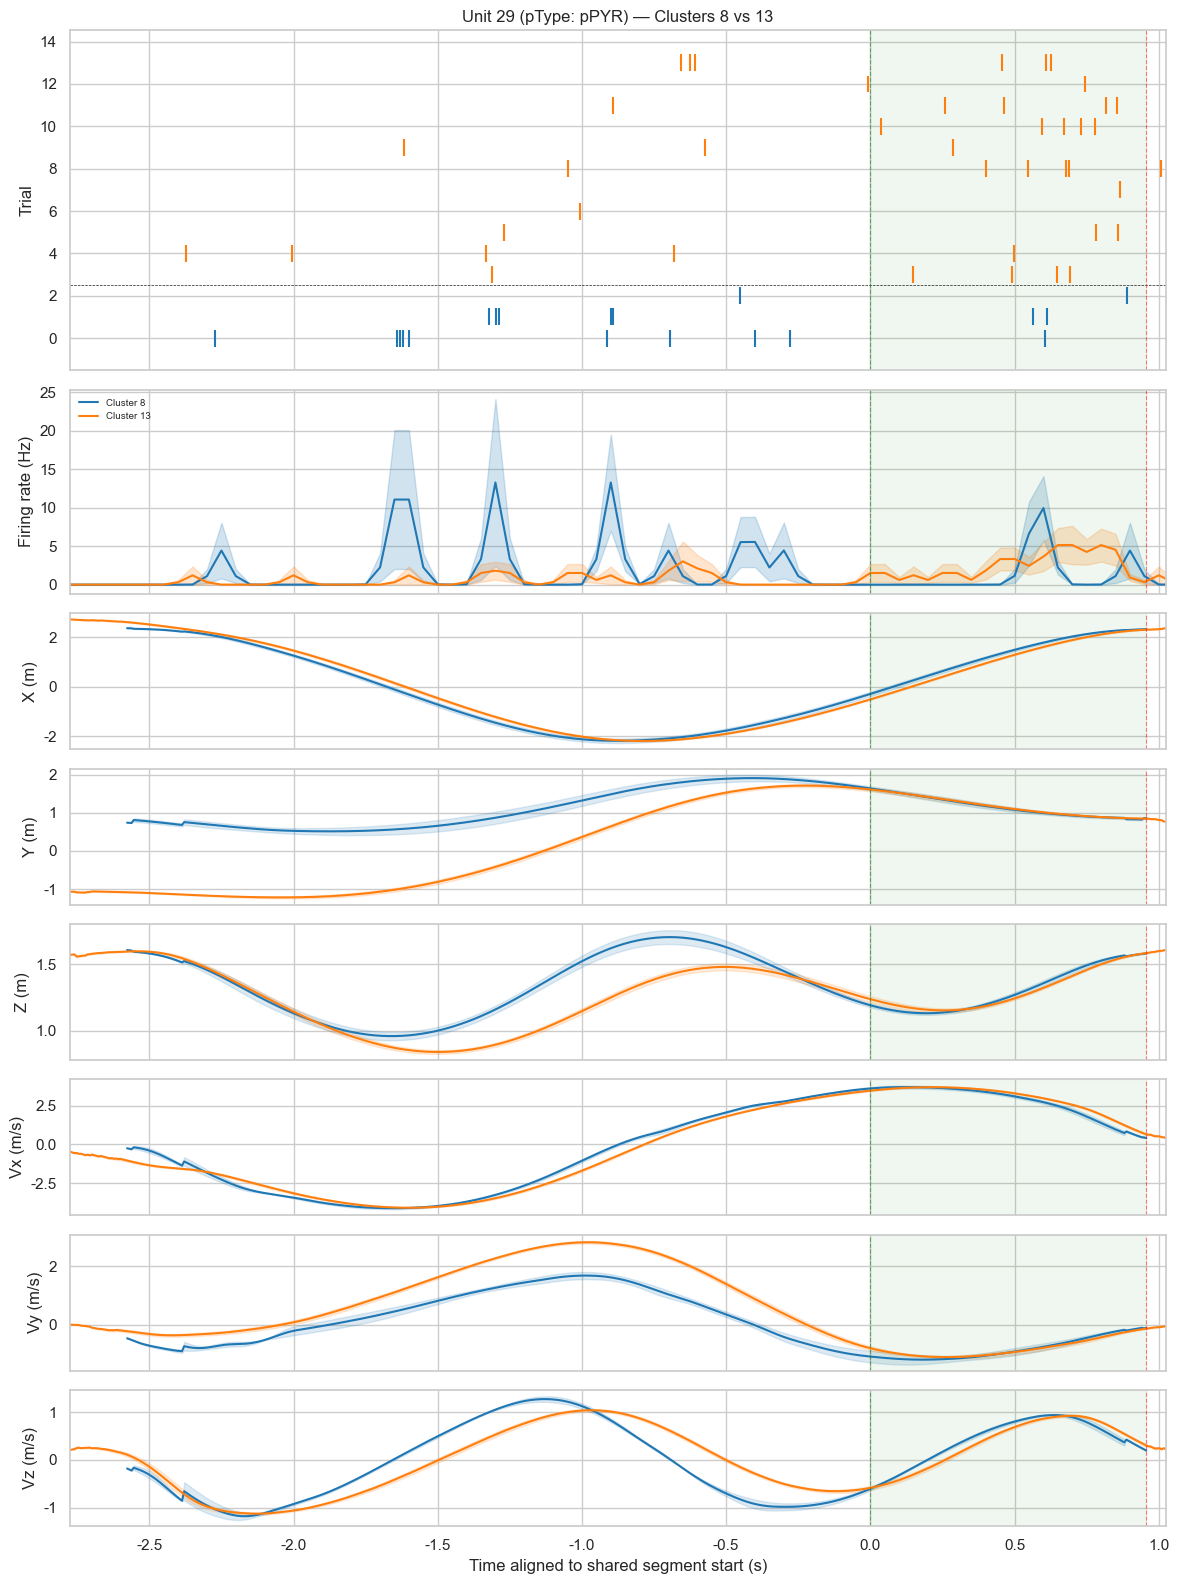

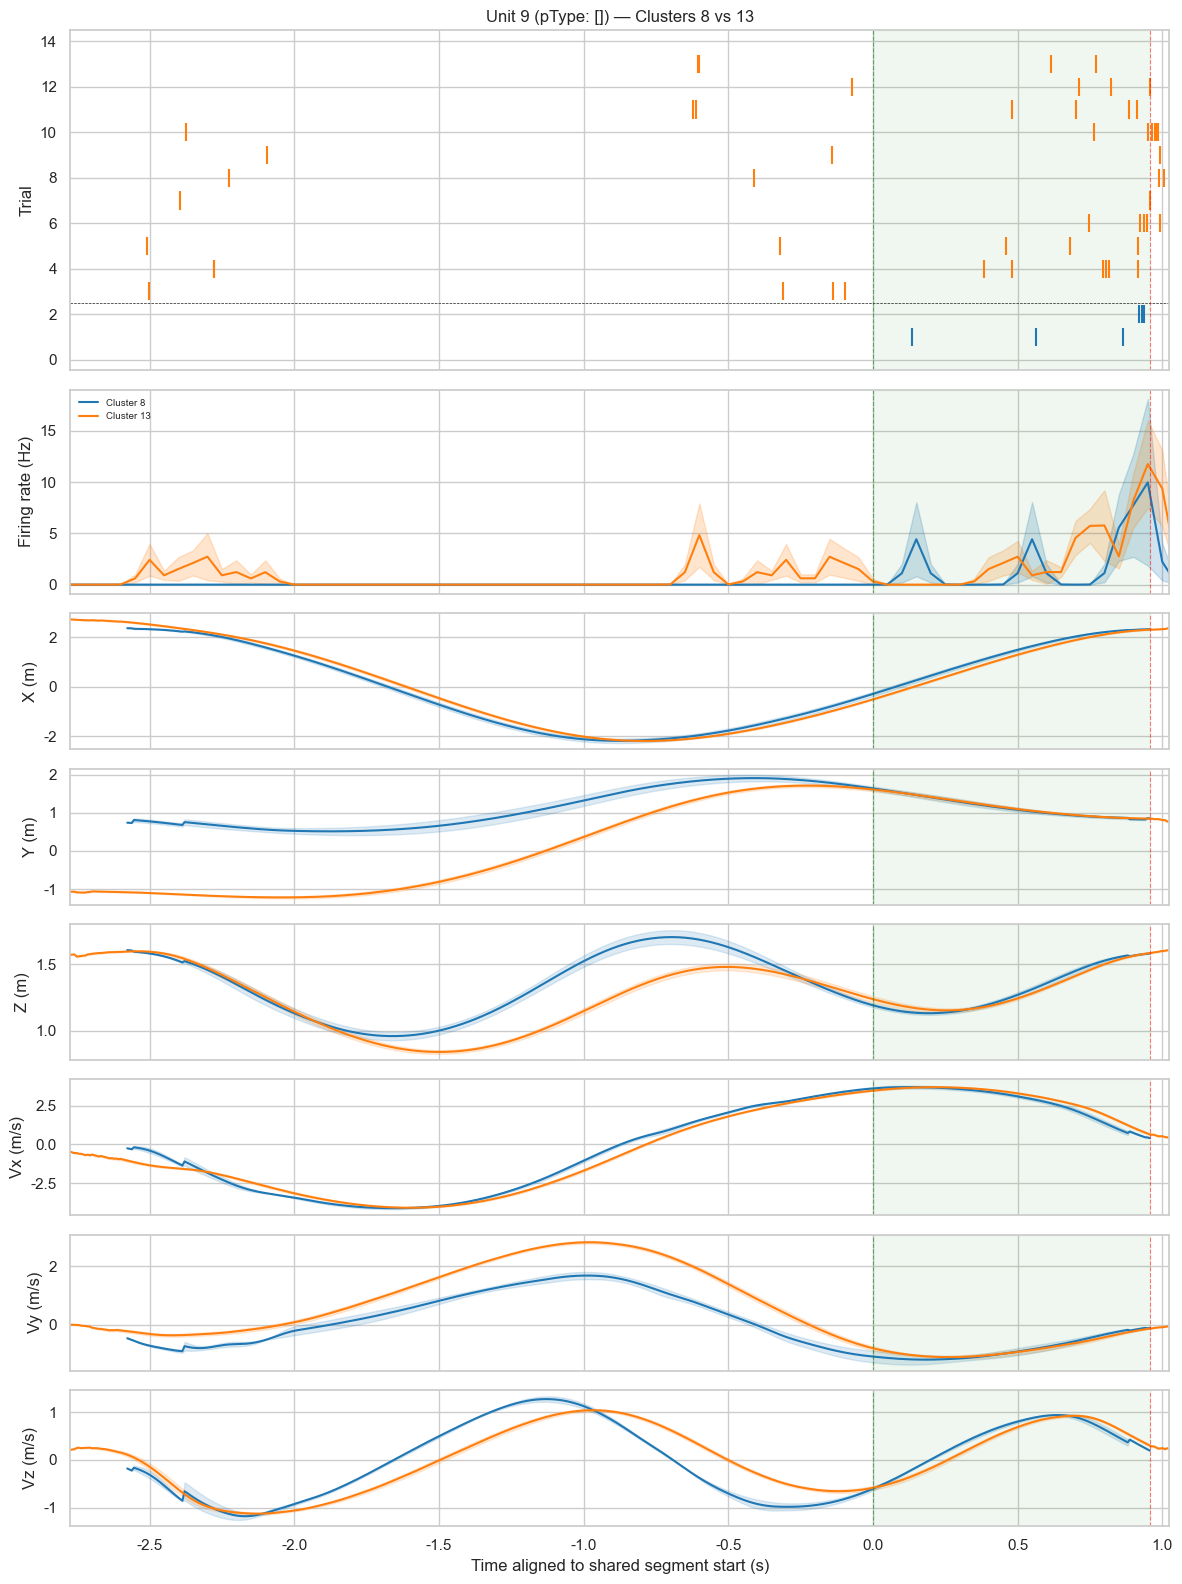

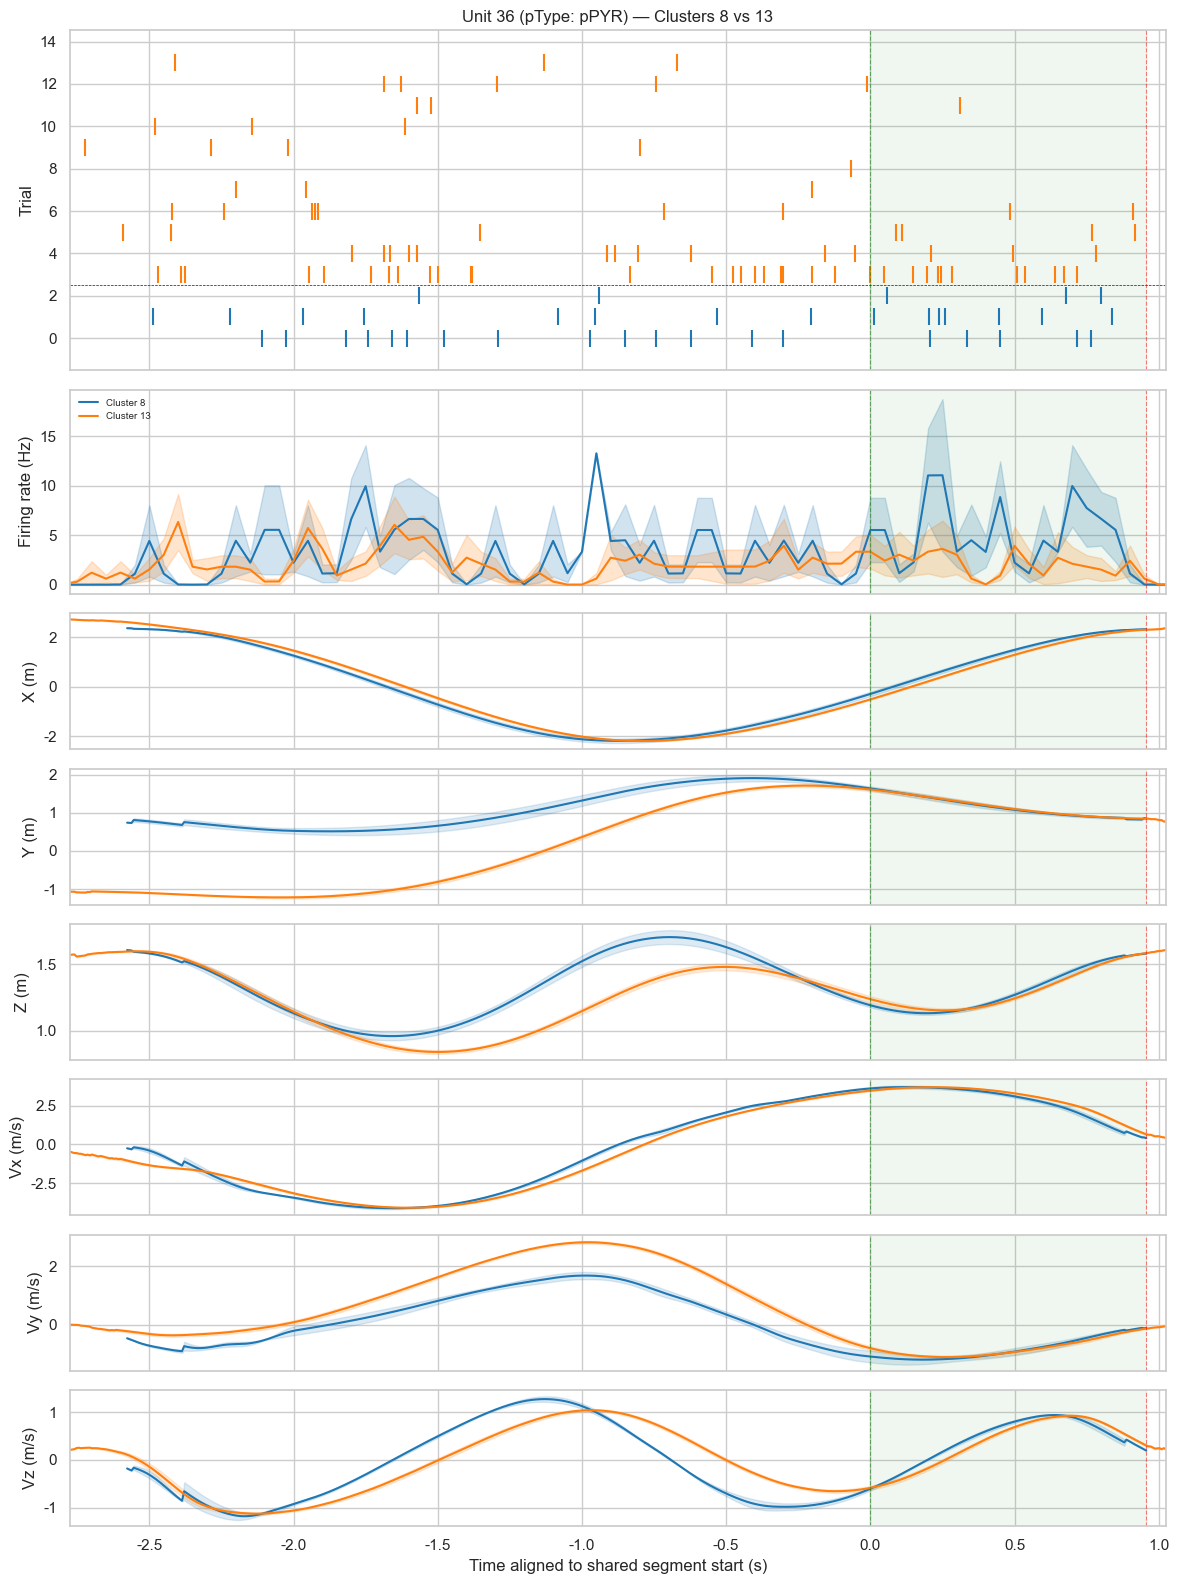

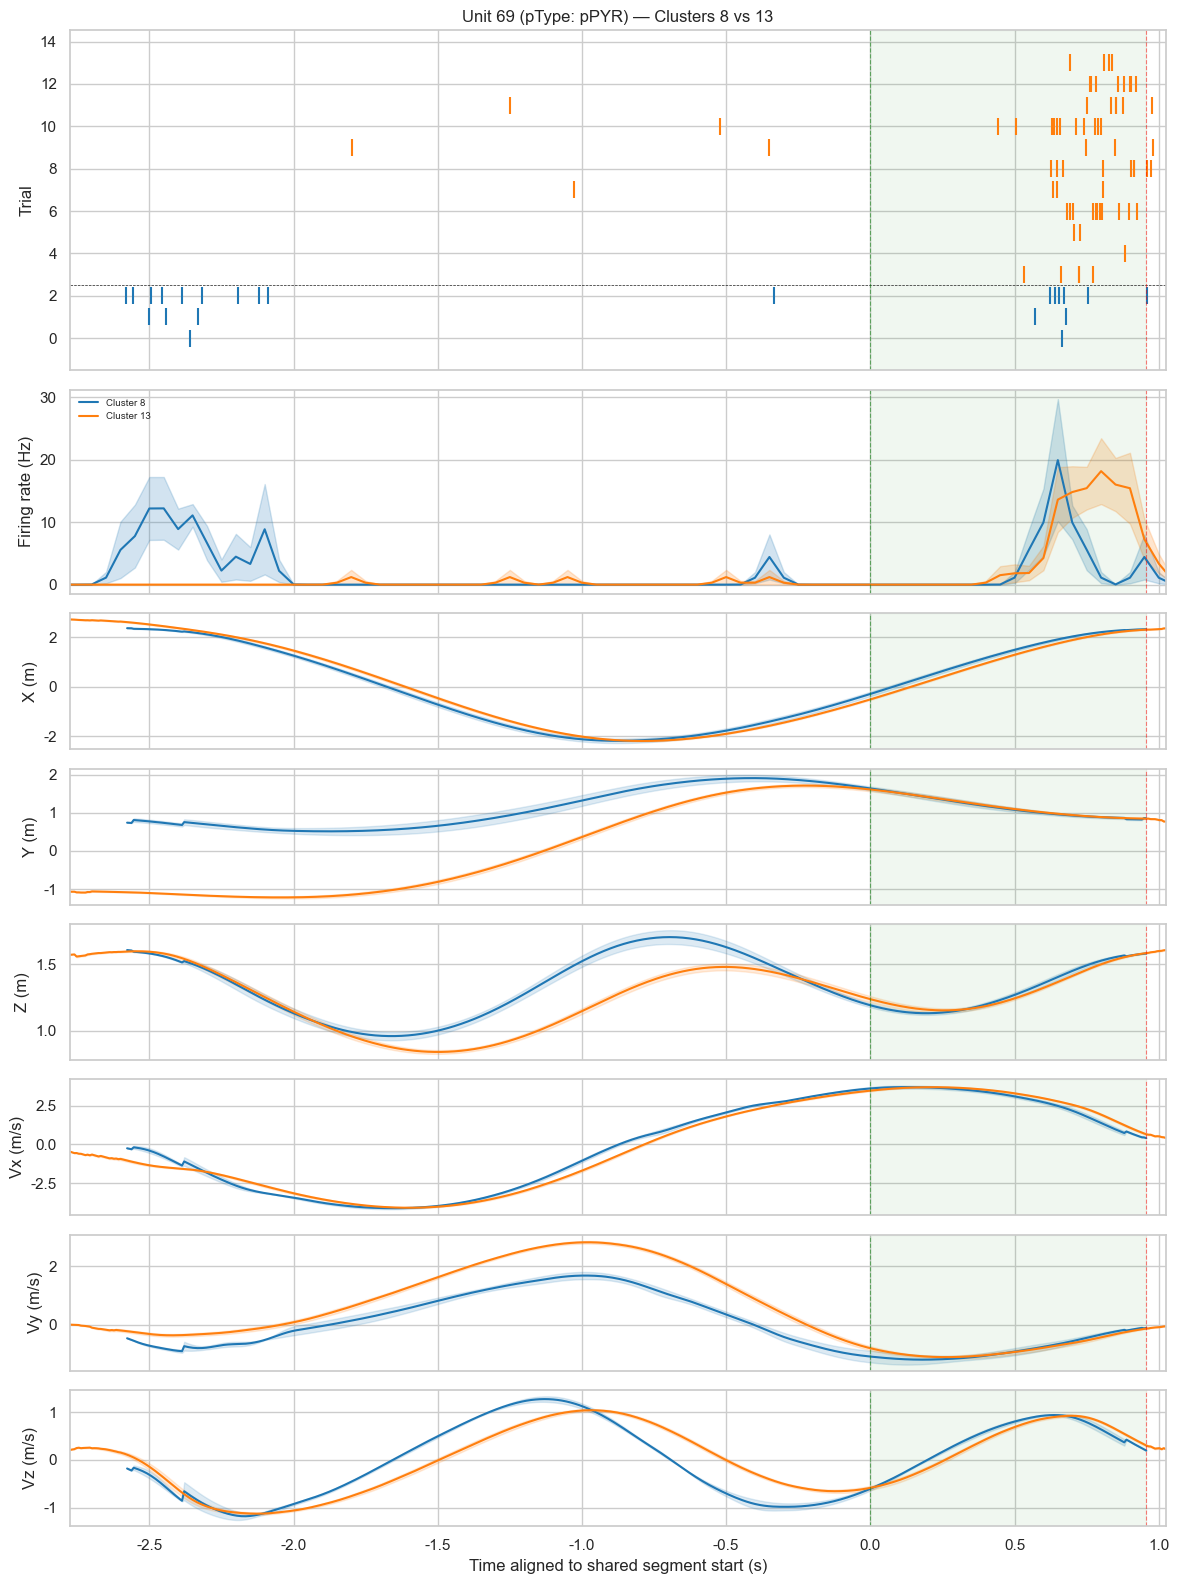

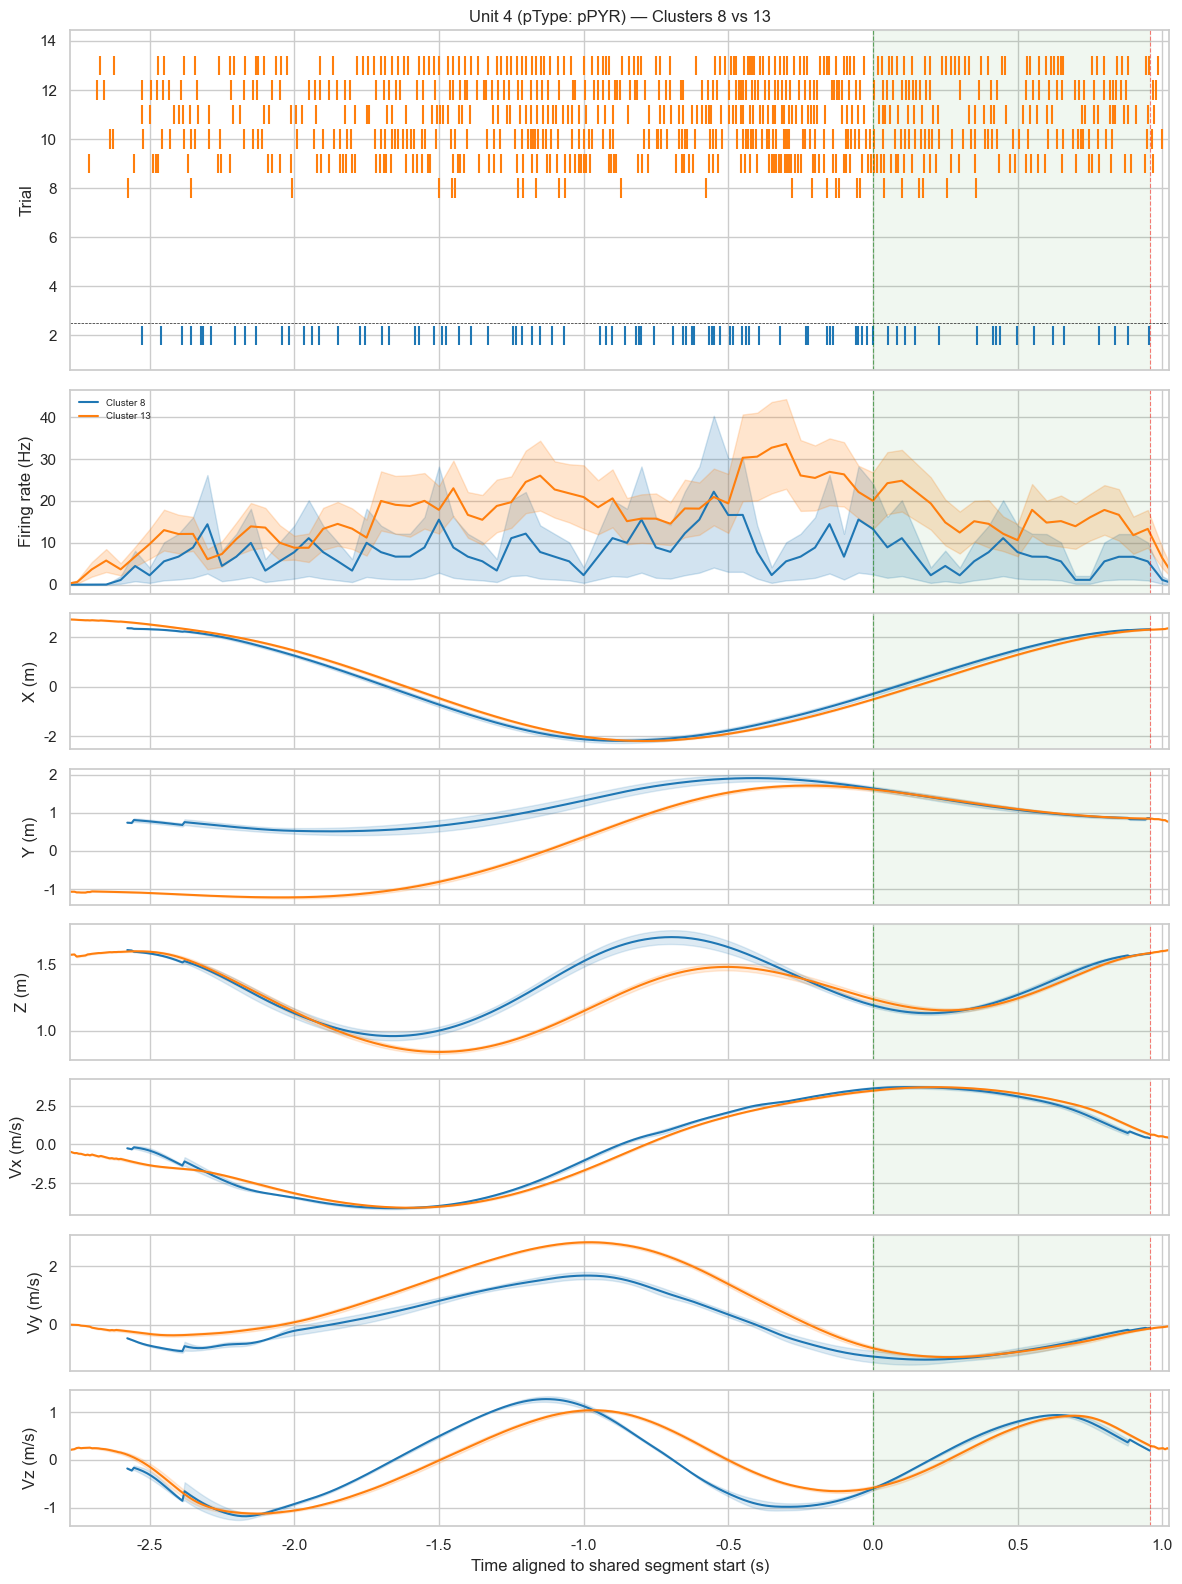

In [180]:
def plot_raster_with_positions(df_aligned, unit_idx, ca, cb, pal=pal,
                               psth_bin=0.050, psth_sigma=0.030):
    """Plot raster + PSTH + position + velocity for one neuron, aligned to shared segment start.

    Parameters
    ----------
    psth_bin : float
        Bin width for PSTH (seconds).
    psth_sigma : float
        Gaussian smoothing sigma for PSTH (seconds). Applied to full timecourse
        before trimming to avoid edge artifacts.
    """
    from scipy.ndimage import gaussian_filter1d

    flights_a = df_aligned[df_aligned['cluster_id'] == ca].reset_index(drop=True)
    flights_b = df_aligned[df_aligned['cluster_id'] == cb].reset_index(drop=True)
    n_a, n_b = len(flights_a), len(flights_b)

    # Common time grid for interpolation
    all_t_min = min(row['t_aligned'][0] for _, row in df_aligned.iterrows())
    all_t_max = max(row['t_aligned'][-1] for _, row in df_aligned.iterrows())

    # PSTH bins — extend beyond visible range for smoothing, then trim
    pad = 5 * psth_sigma
    psth_edges = np.arange(all_t_min - pad, all_t_max + pad + psth_bin, psth_bin)
    psth_centers = (psth_edges[:-1] + psth_edges[1:]) / 2
    sigma_bins = psth_sigma / psth_bin  # sigma in bin units

    # Shared segment boundaries
    median_sh_dur = df_aligned['shared_dur'].median()

    # Layout: raster, PSTH, x, y, z, vx, vy, vz
    fig, axes = plt.subplots(8, 1, figsize=(12, 16), sharex=True,
                              gridspec_kw={'height_ratios': [2.5, 1.5, 1, 1, 1, 1, 1, 1]})

    # --- Raster plot ---
    ax = axes[0]
    trial = 0
    for cluster_flights, color, label in [(flights_a, pal[0], f'Cluster {ca}'),
                                           (flights_b, pal[1], f'Cluster {cb}')]:
        for _, row in cluster_flights.iterrows():
            spk = row['spikes_aligned'][unit_idx]
            ax.eventplot([spk], lineoffsets=trial, linelengths=0.8, colors=[color])
            trial += 1

    ax.axhline(n_a - 0.5, color='k', linewidth=0.5, linestyle='--')
    ax.set_ylabel('Trial')
    ax.set_title(f'Unit {unit_idx} (pType: {str(pType[unit_idx])}) — Clusters {ca} vs {cb}')

    # --- PSTH ---
    ax_psth = axes[1]
    for cluster_flights, color, label, n_fl in [(flights_a, pal[0], f'Cluster {ca}', n_a),
                                                 (flights_b, pal[1], f'Cluster {cb}', n_b)]:
        # Bin spikes per trial, smooth full timecourse, then average
        all_psths = []
        for _, row in cluster_flights.iterrows():
            spk = row['spikes_aligned'][unit_idx]
            counts, _ = np.histogram(spk, bins=psth_edges)
            rate = counts / psth_bin  # convert to Hz
            smoothed = gaussian_filter1d(rate, sigma_bins)
            all_psths.append(smoothed)
        all_psths = np.array(all_psths)
        mean_psth = np.mean(all_psths, axis=0)
        sem_psth = np.std(all_psths, axis=0) / np.sqrt(n_fl)
        ax_psth.plot(psth_centers, mean_psth, color=color, linewidth=1.5, label=label)
        ax_psth.fill_between(psth_centers, mean_psth - sem_psth, mean_psth + sem_psth,
                             color=color, alpha=0.2)
    ax_psth.set_ylabel('Firing rate (Hz)')
    ax_psth.legend(fontsize=7)

    # --- Position traces (x, y, z) ---
    t_common = np.linspace(all_t_min, all_t_max, 500)
    dim_labels = ['X (m)', 'Y (m)', 'Z (m)']
    for dim in range(3):
        ax_p = axes[dim + 2]
        for cluster_flights, color in [(flights_a, pal[0]), (flights_b, pal[1])]:
            interped = []
            for _, row in cluster_flights.iterrows():
                f = interp1d(row['t_aligned'], row['r'][:, dim],
                             bounds_error=False, fill_value=np.nan)
                interped.append(f(t_common))
            interped = np.array(interped)
            mean_val = np.nanmean(interped, axis=0)
            sem_val = np.nanstd(interped, axis=0) / np.sqrt(len(interped))
            ax_p.plot(t_common, mean_val, color=color, linewidth=1.5)
            ax_p.fill_between(t_common, mean_val - sem_val, mean_val + sem_val,
                              color=color, alpha=0.15)
        ax_p.set_ylabel(dim_labels[dim])

    # --- Velocity traces (vx, vy, vz) ---
    vel_labels = ['Vx (m/s)', 'Vy (m/s)', 'Vz (m/s)']
    for dim in range(3):
        ax_v = axes[dim + 5]
        for cluster_flights, color in [(flights_a, pal[0]), (flights_b, pal[1])]:
            interped = []
            for _, row in cluster_flights.iterrows():
                f = interp1d(row['t_aligned'], row['v'][:, dim],
                             bounds_error=False, fill_value=np.nan)
                interped.append(f(t_common))
            interped = np.array(interped)
            mean_val = np.nanmean(interped, axis=0)
            sem_val = np.nanstd(interped, axis=0) / np.sqrt(len(interped))
            ax_v.plot(t_common, mean_val, color=color, linewidth=1.5)
            ax_v.fill_between(t_common, mean_val - sem_val, mean_val + sem_val,
                              color=color, alpha=0.15)
        ax_v.set_ylabel(vel_labels[dim])

    # Shade shared region on all panels
    for ax_i in axes:
        ax_i.axvspan(0, median_sh_dur, color='green', alpha=0.06)
        ax_i.axvline(0, color='green', linewidth=0.8, linestyle='--', alpha=0.5)
        ax_i.axvline(median_sh_dur, color='red', linewidth=0.8, linestyle='--', alpha=0.5)

    axes[-1].set_xlabel('Time aligned to shared segment start (s)')
    # Trim x-axis to data range (not the padded PSTH range)
    axes[-1].set_xlim(all_t_min, all_t_max)
    plt.tight_layout()
    plt.show()


# Plot rasters for top units
for u in top_units:
    plot_raster_with_positions(df_aligned, u, ca, cb)


## Verify Position Alignment (Permutation Tests)

Test that x, y, z positions do NOT significantly differ in the shared segment between the two clusters. This is a necessary check: if positions differ, any neural differences could be explained by place coding alone.

In [ ]:
BIN_DUR = 0.050  # 50 ms bins for PSTH and position comparison
N_PERMS = 1000
rng = np.random.default_rng(42)

# Bin the shared-segment positions into 50ms bins for each flight
# Use aligned time: shared segment is approximately [0, shared_dur]
median_sh_dur = df_aligned['shared_dur'].median()
bin_edges_sh = np.arange(0, median_sh_dur + BIN_DUR, BIN_DUR)
n_bins = len(bin_edges_sh) - 1
bin_centers = (bin_edges_sh[:-1] + bin_edges_sh[1:]) / 2

# Collect binned positions per cluster
def bin_positions_in_shared(flight_row, bin_edges):
    """Bin x,y,z positions within the shared segment into time bins."""
    t_al = flight_row['t_aligned']
    pos = flight_row['r']
    sm = flight_row['shared_mask']
    t_sh = t_al[sm]
    r_sh = pos[sm]
    n_bins = len(bin_edges) - 1
    binned = np.full((n_bins, 3), np.nan)
    for b in range(n_bins):
        mask = (t_sh >= bin_edges[b]) & (t_sh < bin_edges[b + 1])
        if mask.any():
            binned[b] = r_sh[mask].mean(axis=0)
    return binned  # (n_bins, 3)

pos_a = np.stack([bin_positions_in_shared(row, bin_edges_sh)
                  for _, row in df_aligned[df_aligned['cluster_id'] == ca].iterrows()])
pos_b = np.stack([bin_positions_in_shared(row, bin_edges_sh)
                  for _, row in df_aligned[df_aligned['cluster_id'] == cb].iterrows()])
# pos_a shape: (n_flights_a, n_bins, 3), pos_b: (n_flights_b, n_bins, 3)

# Observed mean difference (absolute) per bin per dimension
obs_diff = np.abs(np.nanmean(pos_a, axis=0) - np.nanmean(pos_b, axis=0))  # (n_bins, 3)

# Permutation test: shuffle cluster labels
all_pos = np.concatenate([pos_a, pos_b], axis=0)  # (n_total, n_bins, 3)
n_a_flights = len(pos_a)
n_total = len(all_pos)

perm_diffs = np.zeros((N_PERMS, n_bins, 3))
for p in range(N_PERMS):
    perm_idx = rng.permutation(n_total)
    perm_a = all_pos[perm_idx[:n_a_flights]]
    perm_b = all_pos[perm_idx[n_a_flights:]]
    perm_diffs[p] = np.abs(np.nanmean(perm_a, axis=0) - np.nanmean(perm_b, axis=0))

# P-value: fraction of permutations with difference >= observed
p_values_pos = np.mean(perm_diffs >= obs_diff[None, :, :], axis=0)  # (n_bins, 3)

# Summary: average p-value across bins per dimension
dim_names = ['X', 'Y', 'Z']
print("Position alignment test (shared segment):")
print("  Expect p >> 0.05 (no significant difference)")
for d, name in enumerate(dim_names):
    mean_p = np.nanmean(p_values_pos[:, d])
    min_p = np.nanmin(p_values_pos[:, d])
    print(f"  {name}: mean p={mean_p:.3f}, min p={min_p:.3f}")

# Also test velocity alignment
def bin_velocity_in_shared(flight_row, bin_edges):
    t_al = flight_row['t_aligned']
    vel = flight_row['v']
    sm = flight_row['shared_mask']
    t_sh = t_al[sm]
    v_sh = vel[sm]
    n_bins = len(bin_edges) - 1
    binned = np.full((n_bins, 3), np.nan)
    for b in range(n_bins):
        mask = (t_sh >= bin_edges[b]) & (t_sh < bin_edges[b + 1])
        if mask.any():
            binned[b] = v_sh[mask].mean(axis=0)
    return binned

vel_a = np.stack([bin_velocity_in_shared(row, bin_edges_sh)
                  for _, row in df_aligned[df_aligned['cluster_id'] == ca].iterrows()])
vel_b = np.stack([bin_velocity_in_shared(row, bin_edges_sh)
                  for _, row in df_aligned[df_aligned['cluster_id'] == cb].iterrows()])

obs_vel_diff = np.abs(np.nanmean(vel_a, axis=0) - np.nanmean(vel_b, axis=0))
all_vel = np.concatenate([vel_a, vel_b], axis=0)
perm_vel_diffs = np.zeros((N_PERMS, n_bins, 3))
for p in range(N_PERMS):
    perm_idx = rng.permutation(n_total)
    perm_vel_diffs[p] = np.abs(
        np.nanmean(all_vel[perm_idx[:n_a_flights]], axis=0) -
        np.nanmean(all_vel[perm_idx[n_a_flights:]], axis=0))

p_values_vel = np.mean(perm_vel_diffs >= obs_vel_diff[None, :, :], axis=0)
print("\nVelocity alignment test (shared segment):")
for d, name in enumerate(dim_names):
    mean_p = np.nanmean(p_values_vel[:, d])
    min_p = np.nanmin(p_values_vel[:, d])
    print(f"  {name}: mean p={mean_p:.3f}, min p={min_p:.3f}")

Position alignment test (shared segment):
  Expect p >> 0.05 (no significant difference)
  X: mean p=0.017, min p=0.000
  Y: mean p=0.000, min p=0.000
  Z: mean p=0.008, min p=0.000

Velocity alignment test (shared segment):
  X: mean p=0.079, min p=0.000
  Y: mean p=0.012, min p=0.000
  Z: mean p=0.311, min p=0.000


## Test Neural Coding Differences (PSTH Permutation Tests)

For each neuron, test whether the PSTH in the shared segment differs between the two clusters. If neurons are pure place coders, PSTHs should not differ (same position = same firing). Significant differences indicate non-local coding.

In [ ]:
from statsmodels.stats.multitest import multipletests

def compute_psth(flight_rows, unit_idx, bin_edges):
    """Compute PSTH (spike count per bin) for one unit across flights."""
    n_bins = len(bin_edges) - 1
    counts = np.zeros((len(flight_rows), n_bins))
    for i, (_, row) in enumerate(flight_rows.iterrows()):
        spk = row['spikes_aligned'][unit_idx]
        # Only count spikes in the shared segment [0, shared_dur]
        counts[i], _ = np.histogram(spk, bins=bin_edges)
    return counts  # (n_flights, n_bins)

# Compute PSTHs for all units in shared segment
flights_a = df_aligned[df_aligned['cluster_id'] == ca]
flights_b = df_aligned[df_aligned['cluster_id'] == cb]
n_a_fl, n_b_fl = len(flights_a), len(flights_b)

# Test statistic: sum of absolute differences in mean PSTH across bins
obs_stats = np.zeros(n_units)
psth_a_all = np.zeros((n_units, n_a_fl, n_bins))
psth_b_all = np.zeros((n_units, n_b_fl, n_bins))

for u in range(n_units):
    psth_a_all[u] = compute_psth(flights_a, u, bin_edges_sh)
    psth_b_all[u] = compute_psth(flights_b, u, bin_edges_sh)
    obs_stats[u] = np.sum(np.abs(psth_a_all[u].mean(axis=0) - psth_b_all[u].mean(axis=0)))

# Permutation test: shuffle cluster labels across flights
perm_stats = np.zeros((N_PERMS, n_units))
n_total_fl = n_a_fl + n_b_fl

for p in range(N_PERMS):
    perm_idx = rng.permutation(n_total_fl)
    for u in range(n_units):
        all_psth = np.concatenate([psth_a_all[u], psth_b_all[u]], axis=0)
        perm_a = all_psth[perm_idx[:n_a_fl]]
        perm_b = all_psth[perm_idx[n_a_fl:]]
        perm_stats[p, u] = np.sum(np.abs(perm_a.mean(axis=0) - perm_b.mean(axis=0)))

# P-values
p_values_neural = np.mean(perm_stats >= obs_stats[None, :], axis=0)

# FDR correction
reject, p_corrected, _, _ = multipletests(p_values_neural, method='fdr_bh', alpha=0.05)

n_sig = reject.sum()
print(f"Neural PSTH test (shared segment, {n_units} units):")
print(f"  {n_sig} / {n_units} neurons significant at FDR q<0.05")
print(f"  {(p_values_neural < 0.05).sum()} significant uncorrected at p<0.05")

# Also test divergent segment as positive control
bin_edges_div_before = np.arange(
    df_aligned['t_aligned'].apply(lambda ta: ta[0]).min(),
    0, BIN_DUR)
if len(bin_edges_div_before) > 2:
    obs_stats_div = np.zeros(n_units)
    for u in range(n_units):
        psth_a_div = compute_psth(flights_a, u, bin_edges_div_before)
        psth_b_div = compute_psth(flights_b, u, bin_edges_div_before)
        obs_stats_div[u] = np.sum(np.abs(
            psth_a_div.mean(axis=0) - psth_b_div.mean(axis=0)))

    perm_stats_div = np.zeros((N_PERMS, n_units))
    for p in range(N_PERMS):
        perm_idx = rng.permutation(n_total_fl)
        for u in range(n_units):
            psth_a_div = compute_psth(flights_a, u, bin_edges_div_before)
            psth_b_div = compute_psth(flights_b, u, bin_edges_div_before)
            all_psth_div = np.concatenate([psth_a_div, psth_b_div], axis=0)
            perm_stats_div[p, u] = np.sum(np.abs(
                all_psth_div[perm_idx[:n_a_fl]].mean(axis=0) -
                all_psth_div[perm_idx[n_a_fl:]].mean(axis=0)))

    p_values_div = np.mean(perm_stats_div >= obs_stats_div[None, :], axis=0)
    reject_div, _, _, _ = multipletests(p_values_div, method='fdr_bh', alpha=0.05)
    print(f"\nDivergent segment (positive control, pre-shared):")
    print(f"  {reject_div.sum()} / {n_units} neurons significant at FDR q<0.05")
    print(f"  {(p_values_div < 0.05).sum()} significant uncorrected at p<0.05")

Neural PSTH test (shared segment, 126 units):
  6 / 126 neurons significant at FDR q<0.05
  20 significant uncorrected at p<0.05


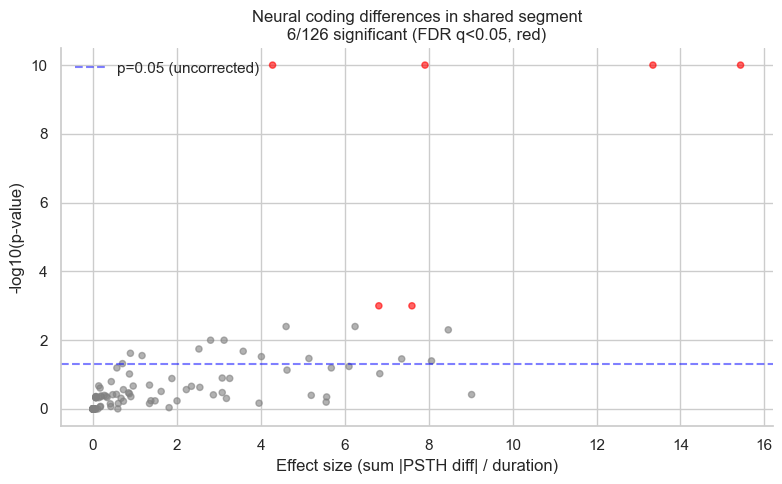

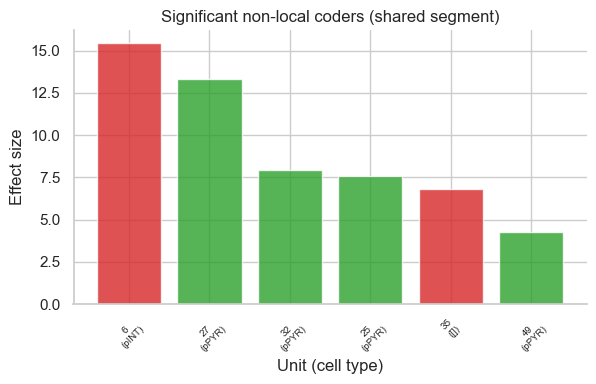

In [ ]:
# Volcano-style plot: effect size vs -log10(p-value)
effect_sizes = obs_stats / (n_bins * BIN_DUR)  # normalize by duration

fig, ax = plt.subplots(figsize=(8, 5))
colors = np.where(reject, 'red', 'gray')
ax.scatter(effect_sizes, -np.log10(p_values_neural + 1e-10), c=colors, alpha=0.6, s=20)
ax.axhline(-np.log10(0.05), color='blue', linestyle='--', alpha=0.5, label='p=0.05 (uncorrected)')
ax.set_xlabel('Effect size (sum |PSTH diff| / duration)')
ax.set_ylabel('-log10(p-value)')
ax.set_title(f'Neural coding differences in shared segment\n'
             f'{n_sig}/{n_units} significant (FDR q<0.05, red)')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

# Ranked bar plot of significant neurons
if n_sig > 0:
    sig_idx = np.where(reject)[0]
    sig_effects = effect_sizes[sig_idx]
    sort_order = np.argsort(sig_effects)[::-1]

    fig, ax = plt.subplots(figsize=(max(6, n_sig * 0.4), 4))
    colors_bar = [pal[2] if str(pType[sig_idx[i]]) == 'pPYR' else pal[3]
                  for i in sort_order]
    ax.bar(range(len(sig_idx)), sig_effects[sort_order], color=colors_bar, alpha=0.8)
    ax.set_xticks(range(len(sig_idx)))
    ax.set_xticklabels([f'{sig_idx[i]}\n({str(pType[sig_idx[i]])})' for i in sort_order],
                       fontsize=7, rotation=45)
    ax.set_xlabel('Unit (cell type)')
    ax.set_ylabel('Effect size')
    ax.set_title('Significant non-local coders (shared segment)')
    sns.despine()
    plt.tight_layout()
    plt.show()

## Save Results

In [ ]:
import pickle, os

save_dir = os.path.join(os.path.dirname(os.getcwd()), 'tmp')
os.makedirs(save_dir, exist_ok=True)

results = dict(
    session_name=session_name,
    df_qualifying=df_qualifying,
    df_aligned=df_aligned,
    p_values_neural=p_values_neural,
    p_corrected=p_corrected,
    reject=reject,
    effect_sizes=effect_sizes,
    obs_stats=obs_stats,
    pType=pType,
    DIST_THRESHOLD=DIST_THRESHOLD,
    BIN_DUR=BIN_DUR,
    N_PERMS=N_PERMS,
)

save_path = os.path.join(save_dir, f'nonlocal_coding_{session_name}.pkl')
with open(save_path, 'wb') as f:
    pickle.dump(results, f)
print(f"Saved results to {save_path}")